Imports e load data

In [1]:
import pandas as pd 
import re
from pathlib import Path
from statistics import median
from collections import Counter
from collections.abc import Callable
import string

* A execução desse notebook depende da existência da camada Bronze criada, seguindo os pipelines anteriores:

  * [preparar_camada_bronze.py](../src/preparar_camada_bronze.py)

Dado nosso primeiro trabalho com a base de entender sua estrutura e limpar os dados gerando nossa camada bronze.
Outra questão permeia uma das aplicações que quero fazer: um LLM local com essa base de conhecimento especialista nas obras.

Para isso irei fazer um RAG.

Mas veja só o problema: algumas obras já têm a divisão semântica a qual chamamos de capítulos e outras não.

Para realizar os chunks eu quero uma abordagem híbrida, já aproveitando parte da semântica do capítulo quando esta existir.

Inicialmente definindo um tamanho de chunk padrão, e.g. 500 caracteres, e aplicar dentro do capítulo quando existir, dividindo o capítulo nessas unidades menores de chunks, e quando não, direto na obra.

Bora lá ver quais obras têm ou não capítulos e como vamos abordar isso.


In [2]:
PROJECT_ROOT = Path("..")

METADATA_PATH = (
    PROJECT_ROOT
    / "Dataset"
    / "metadata"
    / "bronze"
    / "obras_machado_assis_bronze.csv"
)


df = pd.read_csv(
    METADATA_PATH
)

df_obras = df[
    (~df["is_carta"])
    & (~df["is_coletanea"])
].copy()

print(
    "Total no metadata:",
    len(df),
)

print(
    "Obras avaliadas:",
    len(df_obras),
)

Total no metadata: 257
Obras avaliadas: 246


#### utils

In [3]:
def romano_para_int(romano):
    valores = {
        "I": 1,
        "V": 5,
        "X": 10,
        "L": 50,
        "C": 100,
        "D": 500,
        "M": 1000,
    }

    total = 0
    anterior = 0

    for letra in romano.upper()[::-1]:
        valor = valores[letra]

        if valor < anterior:
            total -= valor
        else:
            total += valor
            anterior = valor

    return total


def numero_capitulo(valor):
    valor = str(valor).strip().lower()

    if valor.isdigit():
        return int(valor)

    return romano_para_int(
        valor.upper()
    )

def linha_e_numero_pagina(linha: str) -> bool:
    return bool(
        re.fullmatch(
            r"\s*\d{1,4}\s*",
            linha,
        )
    )

In [4]:
def avaliar_corpus_capitulos(
    df_obras: pd.DataFrame,
    detector: Callable | None = None,
) -> pd.DataFrame:

    if detector is None:
        raise ValueError(
            "É necessário informar uma função detector."
        )

    resultados = []

    for _, row in df_obras.iterrows():

        txt_path = (
            PROJECT_ROOT
            / row["bronze_text_path"]
        )

        if not txt_path.exists():
            continue

        resultado = detector(
            txt_path,
            titulo_obra=row["titulo"],
        )

        resultados.append({
            "titulo": row["titulo"],
            "bronze_text_path": row[
                "bronze_text_path"
            ],
            "tem_capitulos": resultado[
                "tem_capitulos"
            ],
            "regra_capitulo": resultado[
                "regra_capitulo"
            ],
            "qtd_capitulos_detectados": resultado[
                "qtd_capitulos_detectados"
            ],
            "qtd_capitulos_com_titulo": resultado[
                "qtd_capitulos_com_titulo"
            ],
            "pct_capitulos_com_titulo": resultado[
                "pct_capitulos_com_titulo"
            ],
            "mediana_chars_entre_capitulos": resultado[
                "mediana_chars_entre_capitulos"
            ],
        })

    return pd.DataFrame(resultados)

#### V1 Heuristicas

Nossa primeira heuristica baseada no que vi das obras vai pegar variações de: 

* capitulo 1{2,3,4,...,N}
* capitulo I, {II,III,IV,V...} algarismos romanos 

In [ ]:
PADRAO_CAPITULO = re.compile(
    r"""
    ^[ \t]*
    cap[ií]tulo
    [ \t]+
    (?P<numero>
        \d{1,3}           
        |
        [ivxlcdm]+        
    )
    (?:
        [ \t]*
        [.\-–—:]
        [ \t]*
        [^\n]{0,100}
    )?
    [ \t]*$
    """,
    flags=re.IGNORECASE | re.MULTILINE | re.VERBOSE,
)

In [6]:
def check_obra_tem_capitulos(
    txt_path,
    min_capitulos=2,
    min_mediana_chars=200,
):
    txt_path = Path(txt_path)

    texto = txt_path.read_text(
        encoding="utf-8",
        errors="ignore",
    )

    matches = list(
        PADRAO_CAPITULO.finditer(texto)
    )

    capitulos = [
        {
            "cabecalho": match.group(0).strip(),
            "numero": match.group("numero"),
            "inicio": match.start(),
        }
        for match in matches
    ]

  
    distancias = [
        atual["inicio"] - anterior["inicio"]
        for anterior, atual
        in zip(capitulos, capitulos[1:])
    ]

    mediana_distancia = (
        median(distancias)
        if distancias
        else 0
    )

    tem_capitulos = (
        len(capitulos) >= min_capitulos
        and mediana_distancia >= min_mediana_chars
    )

    return {
        "tem_capitulos": tem_capitulos,
        "qtd_capitulos_detectados": len(capitulos),
        "mediana_chars_entre_capitulos": mediana_distancia,
        "capitulos": capitulos,
    }

Avaliando inicialmente: 

* Dom Casmurro 

Escolhido por previamente eu saber que é uma obra  dividida em sublimes capítu...los

In [7]:
PROJECT_ROOT = Path("..")

dom_casmurro_path = (
    PROJECT_ROOT
    / "Dataset"
    / "bronze"
    / "Dom_Casmurro.txt"
)

resultado_dom_casmurro = check_obra_tem_capitulos(
    dom_casmurro_path
)


print(
    "Capítulos detectados:",
    resultado_dom_casmurro["qtd_capitulos_detectados"],
)
capitulos_ordenados = sorted(
    resultado_dom_casmurro["capitulos"],
    key=lambda x: numero_capitulo(
        x["numero"]
    ),
)

for capitulo in capitulos_ordenados:
    numero = numero_capitulo(
        capitulo["numero"]
    )

    print(
        f"{numero:03d} -> "
        f"{capitulo['cabecalho']}"
    )

Capítulos detectados: 145
001 -> CAPÍTULO I
002 -> CAPÍTULO II
003 -> CAPÍTULO III
004 -> CAPÍTULO IV
005 -> CAPÍTULO V
006 -> CAPÍTULO VI
007 -> CAPÍTULO VII
008 -> CAPÍTULO VIII
009 -> CAPÍTULO IX
011 -> CAPÍTULO XI
011 -> CAPÍTULO XI
012 -> CAPÍTULO XII
013 -> CAPÍTULO XIII
014 -> CAPÍTULO XIV
015 -> CAPÍTULO XV
016 -> CAPÍTULO XVI
017 -> CAPÍTULO XVII
018 -> CAPÍTULO XVIII
019 -> CAPÍTULO XIX
020 -> CAPÍTULO XX
021 -> CAPÍTULO XXI
022 -> CAPÍTULO XXII
023 -> CAPÍTULO XXIII
024 -> CAPÍTULO XXIV
026 -> CAPÍTULO XXVI
026 -> CAPÍTULO XXVI
027 -> CAPÍTULO XXVII
028 -> CAPÍTULO XXVIII
029 -> CAPÍTULO XXIX
030 -> CAPÍTULO XXX
031 -> CAPÍTULO XXXI
032 -> CAPÍTULO XXXII
033 -> CAPÍTULO XXXIII
034 -> CAPÍTULO XXXIV
035 -> CAPÍTULO XXXV
036 -> CAPÍTULO XXXVI
037 -> CAPÍTULO XXXVII
038 -> CAPÍTULO XXXVIII
039 -> CAPÍTULO XXXIX
040 -> CAPÍTULO XL
041 -> CAPÍTULO XLI
042 -> CAPÍTULO XLII
043 -> CAPÍTULO XLIII
044 -> CAPÍTULO XLIV
045 -> CAPÍTULO XLV
046 -> CAPÍTULO XLVI
047 -> CAPÍTULO XLVII
048

De cara ja tem algo errado, temos 146 capitulos detectados pela heuristica, mas o ultimo é o  CXLVIII , correspondente ao capitulo  148 ...
Além disso, temos capitulos repetidos : 
* 011 -> CAPÍTULO XI
* 011 -> CAPÍTULO XI

Vamos investigar

Avaliando os repetidos: 

In [8]:
numeros = [
    numero_capitulo(
        capitulo["numero"]
    )
    for capitulo in resultado_dom_casmurro["capitulos"]
]

contagem = Counter(
    numeros
)

duplicados = {
    numero: qtd
    for numero, qtd in contagem.items()
    if qtd > 1
}

print(
    "Duplicados:",
    duplicados,
)

Duplicados: {11: 2, 26: 2, 60: 2, 95: 2}


Deixa eu olhar isso mais de perto diretamente na fonte.

Dom Casmurro, na base, tem capítulos repetidos no próprio PDF!

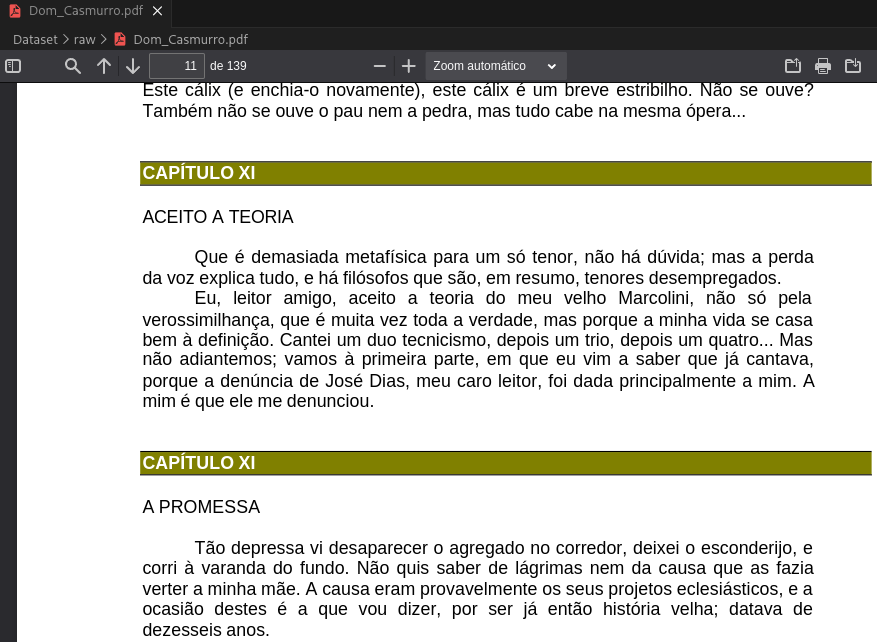

Que barra, hein? Vou ter que decidir o que fazer com isso, porque essa situação levanta dúvidas sobre a própria fonte. Nosso extrator retornou 145 capítulos, mas, pela numeração em algarismos romanos, chegamos até o capítulo 148:

* 148 -> CAPÍTULO CXLVIII

Em Dom Casmurro, especificamente, os capítulos possuem títulos logo após as âncoras.  Entretanto, ainda não sei se esse padrão se repete em outras obras.
Avaliando : 
* Memórias Póstumas de Brás Cubas
*  O Alienista 

Ambos também possuem títulos de capítulos.

Para seguir, vou considerar o extrator como correto, dado que ele extraiu até o ultimo capitulo do livro de fato e tentar extrair também o título de cada capítulo.

#### V2 Heuristicas

Extração dos títulos disponiveis inicialmente e do formato anterior de capítulos

In [9]:
PADRAO_CAPITULO = re.compile(
    r"""
    ^[ \t]*
    cap[ií]tulo
    [ \t]+
    (?P<numero>
        \d{1,3}
        |
        [ivxlcdm]+
    )
    (?:
        [ \t]*
        [\-–—.:]
        [ \t]*
        (?P<titulo_inline>[^\n]+)
    )?
    [ \t]*$
    """,
    flags=re.IGNORECASE | re.MULTILINE | re.VERBOSE,
)



In [10]:
def encontrar_titulo_apos_capitulo(
    linhas: list[str],
    indice_capitulo: int,
    max_palavras_titulo: int = 10,
) -> dict:

    for i in range(
        indice_capitulo + 1,
        min(indice_capitulo + 6, len(linhas)),
    ):
        linha_original = linhas[i]
        linha = linha_original.strip()

        if not linha:
            continue

        if linha_e_numero_pagina(linha):
            continue

        # Regra titulo: primeira linha inteira após o capítulo.
        if (
            linha_original.endswith("\n")
            and len(linha.split()) <= max_palavras_titulo
        ):
            return {
                "titulo": linha,
                "regra_titulo": "proxima_linha",
            }

        return {
            "titulo": None,
            "regra_titulo": None,
        }

    return {
        "titulo": None,
        "regra_titulo": None,
    }

In [11]:
def check_obra_tem_capitulos_v2(
    txt_path,
    titulo_obra=None,
    min_capitulos=2,
    min_mediana_chars=200,
):
    txt_path = Path(txt_path)

    texto = txt_path.read_text(
        encoding="utf-8",
        errors="ignore",
    )

    linhas = texto.splitlines(
        keepends=True
    )

    titulo_norm = (
        str(titulo_obra).strip().casefold()
        if titulo_obra
        else ""
    )

    padrao_capitulo = PADRAO_CAPITULO
    regra_capitulo = "capitulo_explicito"

    capitulos = []
    posicao = 0

    for indice_linha, linha_original in enumerate(
        linhas
    ):
        linha = linha_original.strip()

        match = padrao_capitulo.match(
            linha
        )

        if match:
            numero = match.group(
                "numero"
            )

            titulo_inline = (
                match.groupdict().get(
                    "titulo_inline"
                )
            )

            if titulo_inline:
                titulo = titulo_inline.strip()
                regra_titulo = "inline"

            else:
                resultado_titulo = (
                    encontrar_titulo_apos_capitulo(
                        linhas=linhas,
                        indice_capitulo=indice_linha,
                    )
                )

                titulo = resultado_titulo[
                    "titulo"
                ]

                regra_titulo = resultado_titulo[
                    "regra_titulo"
                ]

            capitulos.append({
                "numero": numero,
                "cabecalho": linha,
                "titulo": titulo,
                "regra_titulo": regra_titulo,
                "regra_capitulo": regra_capitulo,
                "linha": indice_linha,
                "inicio": posicao,
            })

        posicao += len(
            linha_original
        )

    distancias = [
        atual["inicio"]
        - anterior["inicio"]
        for anterior, atual
        in zip(
            capitulos,
            capitulos[1:],
        )
    ]

    mediana_distancia = (
        median(distancias)
        if distancias
        else 0
    )

    tem_capitulos = (
        len(capitulos)
        >= min_capitulos
        and mediana_distancia
        >= min_mediana_chars
    )

    qtd_com_titulo = sum(
        capitulo["titulo"] is not None
        for capitulo in capitulos
    )

    return {
        "tem_capitulos": tem_capitulos,
        "regra_capitulo": (
            regra_capitulo
            if capitulos
            else None
        ),
        "qtd_capitulos_detectados": len(
            capitulos
        ),
        "qtd_capitulos_com_titulo": qtd_com_titulo,
        "pct_capitulos_com_titulo": (
            qtd_com_titulo
            / len(capitulos)
            if capitulos
            else 0
        ),
        "mediana_chars_entre_capitulos": (
            mediana_distancia
        ),
        "capitulos": capitulos,
    }

Avaliando em obras individuais distintas :

##### Dom casmurro  

In [12]:
PROJECT_ROOT = Path("..")

dom_casmurro_path = (
    PROJECT_ROOT
    / "Dataset"
    / "bronze"
    / "Dom_Casmurro.txt"
)

resultado_dom_casmurro = check_obra_tem_capitulos_v2(
    dom_casmurro_path,
    titulo_obra="Dom_Casmurro.txt"
)

print(
    "Capítulos:",
    resultado_dom_casmurro[
        "qtd_capitulos_detectados"
    ],
)

print(
    "Com título:",
    resultado_dom_casmurro[
        "qtd_capitulos_com_titulo"
    ],
)

print(
    "Percentual com título:",
    round(
        resultado_dom_casmurro[
            "pct_capitulos_com_titulo"
        ] * 100,
        2,
    ),
    "%",
)

print()

for capitulo in resultado_dom_casmurro[
    "capitulos"
]:
    print(
        f"{capitulo['numero']:>8} | "
        f"{capitulo['titulo']}"
    )

Capítulos: 145
Com título: 145
Percentual com título: 100.0 %

       I | DO TÍTULO
      II | DO LIVRO
     III | A DENÚNCIA
      IV | UM DEVER AMARÍSSIMO!
       V | O AGREGADO
      VI | TIO COSME
     VII | D. GLÓRIA
    VIII | E TEMPO
      IX | A ÓPERA
      XI | ACEITO A TEORIA
      XI | A PROMESSA
     XII | NA VARANDA
    XIII | CAPITU
     XIV | A INSCRIÇÃO
      XV | OUTRA VOZ REPENTINA
     XVI | O ADMINISTRADOR INTERINO
    XVII | OS VERMES "ELE FERE E CURA!"
   XVIII | UM PLANO
     XIX | SEM FALTA
      XX | MIL PADRE-NOSSOS E MIL AVE-MARIAS
     XXI | PRIMA JUSTINA
    XXII | SENSAÇÕES ALHEIAS
   XXIII | PRAZO DADO
    XXIV | DE MÃE E DE SERVO
    XXVI | NO PASSEIO PÚBLICO
    XXVI | AS LEIS SÃO BELAS
   XXVII | AO PORTÃO
  XXVIII | NA RUA
    XXIX | O IMPERADOR
     XXX | O SANTÍSSlMO
    XXXI | AS CURIOSIDADES DE CAPITU
   XXXII | OLHOS DE RESSACA
  XXXIII | O PENTEADO
   XXXIV | SOU HOMEM!
    XXXV | O PROTONOTÁRIO APOSTÓLICO
   XXXVI | IDÉIA SEM PERNAS E IDÉIA SEM

avaliando manualmente tem os capitulos e titulos todos, apesar, de que, no proprio pdf estejam errados a numeração 

##### O alienista

In [13]:
PROJECT_ROOT = Path("..")

O_Alienista = (
    PROJECT_ROOT
    / "Dataset"
    / "bronze"
    / "O_Alienista.txt"
)

resultado_o_alienista = check_obra_tem_capitulos_v2(
    O_Alienista
)

print(
    "Capítulos:",
    resultado_o_alienista[
        "qtd_capitulos_detectados"
    ],
)

print(
    "Com título:",
    resultado_o_alienista[
        "qtd_capitulos_com_titulo"
    ],
)

print(
    "Percentual com título:",
    round(
        resultado_o_alienista[
            "pct_capitulos_com_titulo"
        ] * 100,
        2,
    ),
    "%",
)

print()

for capitulo in resultado_o_alienista[
    "capitulos"
]:
    print(
        f"{capitulo['numero']:>8} | "
        f"{capitulo['titulo']}"
    )

Capítulos: 13
Com título: 13
Percentual com título: 100.0 %

       I | DE COMO ITAGUAÍ GANHOU UMA CASA DE ORATES
      II | TORRENTES DE LOUCOS
     III | DEUS SABE O QUE FAZ
      IV | UMA TEORIA NOVA
       V | O TERROR
      VI | A REBELIÃO
     VII | O INESPERADO
    VIII | AS ANGÚSTIAS  DO BOTICÁRIO
      IX | DOIS LINDOS CASOS
       X | RESTAURAÇÃO
      XI | O ASSOMBRO DE ITAGUAÍ
     XII | O FINAL DO § 4º.
    XIII | PLUS  ULTRA!


avaliando manualmente está ok também titulos e numeração de capitulos, este nao tem erros na capitularização 

##### Memorias Postumas de Brás Cubas

In [14]:
PROJECT_ROOT = Path("..")

memorias_postumas_path = (
    PROJECT_ROOT
    / "Dataset"
    / "bronze"
    / "Memórias_Póstumas_de_Brás_Cubas.txt"
)

resultado_memorias_postumas = check_obra_tem_capitulos_v2(
    memorias_postumas_path
)

print(
    "Tem capítulos:",
    resultado_memorias_postumas["tem_capitulos"],
)

print(
    "Capítulos:",
    resultado_memorias_postumas[
        "qtd_capitulos_detectados"
    ],
)

print(
    "Com título:",
    resultado_memorias_postumas[
        "qtd_capitulos_com_titulo"
    ],
)

print(
    "Percentual com título:",
    round(
        resultado_memorias_postumas[
            "pct_capitulos_com_titulo"
        ] * 100,
        2,
    ),
    "%",
)

print()

for capitulo in resultado_memorias_postumas[
    "capitulos"
]:
    print(
        f"{capitulo['numero']:>8} | "
        f"{capitulo['titulo']}"
    )

Tem capítulos: True
Capítulos: 160
Com título: 158
Percentual com título: 98.75 %

       I | Óbito do Autor
      II | O Emplasto
     III | Genealogia
      IV | A Idéia Fixa
       V | Em Que Aparece a Orelha de Uma Senhora
      VI | Chimène, qui L Eût Dit? Rodrigue, qui L'Eût Cru?
     VII | O Delírio
    VIII | Razão Contra Sandice
      IX | Transição
       X | Naquele Dia...
      XI | O Menino é Pai do Homem
     XII | Um Episódio de 1814
    XIII | Um Salto
     XIV | O Primeiro Beijo
      XV | Marcela
     XVI | Uma Reflexão Imoral
    XVII | Do Trapézio e outras coisas
   XVIII | Visão do Corredor
     XIX | A Bordo
      XX | Bacharelo-me
     XXI | O Almocreve
    XXII | Volta ao Rio
   XXIII | Triste, mas Curto
    XXIV | Curto, mais Alegre
     XXV | Na Tijuca
    XXVI | O Autor Hesita
   XXVII | Virgília
  XXVIII | Contanto Que...
    XXIX | A Visita
     XXX | A Flor da Moita
    XXXI | A Borboleta Preta
   XXXII | Coxa de Nascença
  XXXIII | Bem-Aventurados os que 

Em Memórias Postumas o capitulo que teve None: 
* CXXVI

De fato não tem titulo: 

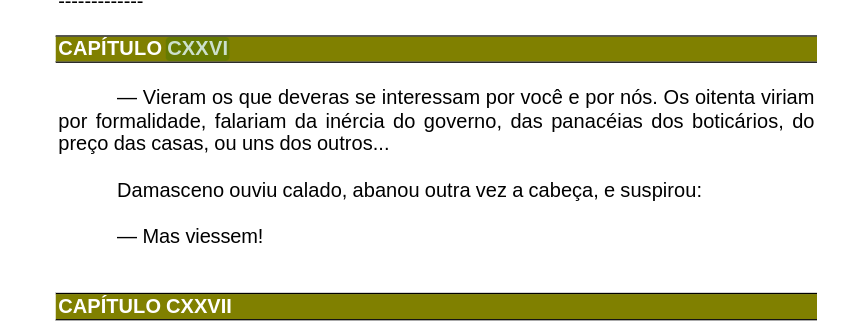

##### Bora lá testar em todas as obras agora e ver o que conseguimos: 

Vamos avaliar apenas as obras, tirando dessa análise coletaneas e cartas

In [15]:
df_capitulos_v2 = avaliar_corpus_capitulos(
    df_obras,
    detector=check_obra_tem_capitulos_v2,
)

In [16]:
df_capitulos_v2[
    df_capitulos_v2["tem_capitulos"]
][
    [
        "titulo",
        "qtd_capitulos_detectados",
        "qtd_capitulos_com_titulo",
        "pct_capitulos_com_titulo",
    ]
].sort_values(
    "qtd_capitulos_detectados",
    ascending=False,
)

,titulo,qtd_capitulos_detectados,qtd_capitulos_com_titulo,pct_capitulos_com_titulo
191,Quincas Borba,200,28,0.140000
113,Memórias Póstumas de Brás Cubas,160,158,0.987500
66,Dom Casmurro,145,145,1.000000
75,Esaú e Jacó,121,121,1.000000
94,História de Quinze Dias,58,12,0.206897
124,Notas Semanais,42,3,0.071429
180,Ponto de Vista,29,29,1.000000
91,Helena,28,2,0.071429
15,A Mão e a Luva,19,19,1.000000
97,Iaiá Garcia,17,1,0.058824


Olhar os que não tiveram capitulos: 

In [17]:
df_capitulos_v2[
    ~df_capitulos_v2["tem_capitulos"]
][
    [
        "titulo",
        "qtd_capitulos_detectados",
        "qtd_capitulos_com_titulo",
        "pct_capitulos_com_titulo",
    ]
].sort_values(
    "qtd_capitulos_detectados",
    ascending=False,
)

,titulo,qtd_capitulos_detectados,qtd_capitulos_com_titulo,pct_capitulos_com_titulo
121,Na Arca,1,0,0.0
0,A Carteira,0,0,0.0
2,A Causa Secreta,0,0,0.0
4,A Chinela Turca,0,0,0.0
5,A Desejada das Gentes,0,0,0.0
...,...,...,...,...
241,Viver,0,0,0.0
242,Viver!,0,0,0.0
243,Vênus! divina vênus!,0,0,0.0
244,Última receita,0,0,0.0


Opa, tivemos um pequeno edge case em "Na Arca", que teve um capítulo detectado, mas parece que não teve palavras suficientes para passar como capítulo.

Avaliando o PDF, ele tem uma estrutura diferente, sendo numerado com letras.

e.g.: Capítulo A, Capítulo B e Capítulo C.

Vou criar uma regra especial só para esse case e então procurar por falsos negativos: a heurística disse que não tinha capítulos, mas tem.


In [18]:
PADRAO_CAPITULO_NA_ARCA = re.compile(
    r"""
    ^[ \t]*
    cap[ií]tulo
    [ \t]+
    (?P<numero>
        [a-z]
    )
    [ \t]*$
    """,
    flags=re.IGNORECASE | re.MULTILINE | re.VERBOSE,
)

In [19]:
def check_obra_tem_capitulos_v2_5(
    txt_path,
    titulo_obra=None,
    min_capitulos=2,
    min_mediana_chars=200,
):
    txt_path = Path(txt_path)

    texto = txt_path.read_text(
        encoding="utf-8",
        errors="ignore",
    )

    linhas = texto.splitlines(
        keepends=True
    )

    titulo_norm = (
        str(titulo_obra).strip().casefold()
        if titulo_obra
        else ""
    )

    if titulo_norm == "na arca":
        padrao_capitulo = (
            PADRAO_CAPITULO_NA_ARCA
        )
        regra_capitulo = (
            "capitulo_letra"
        )
    else:
        padrao_capitulo = (
            PADRAO_CAPITULO
        )
        regra_capitulo = (
            "capitulo_explicito"
        )

    capitulos = []
    posicao = 0

    for indice_linha, linha_original in enumerate(
        linhas
    ):
        linha = linha_original.strip()

        match = padrao_capitulo.match(
            linha
        )

        if match:
            numero = match.group(
                "numero"
            )

            titulo_inline = (
                match.groupdict().get(
                    "titulo_inline"
                )
            )

            if titulo_inline:
                titulo = (
                    titulo_inline.strip()
                )
                regra_titulo = (
                    "inline"
                )
            else:
                resultado_titulo = (
                    encontrar_titulo_apos_capitulo(
                        linhas=linhas,
                        indice_capitulo=indice_linha,
                    )
                )

                titulo = resultado_titulo[
                    "titulo"
                ]

                regra_titulo = resultado_titulo[
                    "regra_titulo"
                ]

            capitulos.append({
                "numero": numero,
                "cabecalho": linha,
                "titulo": titulo,
                "regra_titulo": regra_titulo,
                "regra_capitulo": regra_capitulo,
                "linha": indice_linha,
                "inicio": posicao,
            })

        posicao += len(
            linha_original
        )

    distancias = [
        atual["inicio"]
        - anterior["inicio"]
        for anterior, atual
        in zip(
            capitulos,
            capitulos[1:],
        )
    ]

    mediana_distancia = (
        median(distancias)
        if distancias
        else 0
    )

    tem_capitulos = (
        len(capitulos)
        >= min_capitulos
        and mediana_distancia
        >= min_mediana_chars
    )

    qtd_com_titulo = sum(
        capitulo["titulo"]
        is not None
        for capitulo in capitulos
    )

    return {
        "tem_capitulos": tem_capitulos,
        "regra_capitulo": (
            regra_capitulo
            if capitulos
            else None
        ),
        "qtd_capitulos_detectados": len(
            capitulos
        ),
        "qtd_capitulos_com_titulo": qtd_com_titulo,
        "pct_capitulos_com_titulo": (
            qtd_com_titulo
            / len(capitulos)
            if capitulos
            else 0
        ),
        "mediana_chars_entre_capitulos": (
            mediana_distancia
        ),
        "capitulos": capitulos,
    }

In [20]:
df_capitulos_v2_5 = avaliar_corpus_capitulos(
    df_obras,
    detector=check_obra_tem_capitulos_v2_5,
)

In [21]:
df_capitulos_v2_5[
    ~df_capitulos_v2_5["tem_capitulos"]
][
    [
        "titulo",
        "qtd_capitulos_detectados",
        "qtd_capitulos_com_titulo",
        "pct_capitulos_com_titulo",
        "mediana_chars_entre_capitulos",
    ]
].sort_values(
    "qtd_capitulos_detectados",
    ascending=False,
)

,titulo,qtd_capitulos_detectados,qtd_capitulos_com_titulo,pct_capitulos_com_titulo,mediana_chars_entre_capitulos
0,A Carteira,0,0,0.0,0.0
1,A Cartomante,0,0,0.0,0.0
2,A Causa Secreta,0,0,0.0,0.0
4,A Chinela Turca,0,0,0.0,0.0
5,A Desejada das Gentes,0,0,0.0,0.0
...,...,...,...,...,...
241,Viver,0,0,0.0,0.0
242,Viver!,0,0,0.0,0.0
243,Vênus! divina vênus!,0,0,0.0,0.0
244,Última receita,0,0,0.0,0.0


Supimpa, pouco a pouco vamos resolvendo os casos! E melhorando nossas heuristicas !

Sempre que tratamos de detecção de algo, é importante estarmos cientes do que nosso detector pega ou não. Como nesse projeto é muito importante extrairmos o máximo das divsões semanticas pré existentes, vamos começar avaliando falsos negativos.

Investigar de maneira bem permissiva agora, sempre que aparecer a palavra capitulo, certamente apareceram várias, porque essa palavra pode ser usada ao longo dos textos do proprios personagens elucidando situações para encontramos algo que nossas heuristícas podem ter deixado de fora 

In [ ]:
PADROES_INVESTIGACAO = {
    "palavra_capitulo": re.compile(
        r"\bcap[ií]tulo\b",
        flags=re.IGNORECASE,
    ),

    # Numerais romanos isolados como possível heading
    "romano_isolado": re.compile(
        r"(?mi)^\s*"
        r"(?:i|ii|iii|iv|v|vi|vii|viii|ix|x|"
        r"xi|xii|xiii|xiv|xv|xvi|xvii|xviii|xix|xx)"
        r"\s*$"
    ),
}

In [23]:
df_sem_capitulos = df_capitulos_v2_5[
    ~df_capitulos_v2_5["tem_capitulos"]
].copy()


resultados_investigacao = []

for _, row in df_sem_capitulos.iterrows():

    txt_path = (
        PROJECT_ROOT
        / row["bronze_text_path"]
    )

    texto = txt_path.read_text(
        encoding="utf-8",
        errors="ignore",
    )

    resultado = {
        "titulo": row["titulo"],
        "bronze_text_path": row[
            "bronze_text_path"
        ],
    }

    for nome, padrao in PADROES_INVESTIGACAO.items():
        resultado[nome] = len(
            padrao.findall(texto)
        )

    resultados_investigacao.append(
        resultado
    )


df_investigacao = pd.DataFrame(
    resultados_investigacao
)

In [24]:
colunas_sinais = list(
    PADROES_INVESTIGACAO.keys()
)

df_investigacao["total_sinais"] = (
    df_investigacao[
        colunas_sinais
    ].sum(axis=1)
)

df_investigacao[
    df_investigacao["total_sinais"] > 0
].sort_values(
    "total_sinais",
    ascending=False,
)[
    [
        "titulo",
        "palavra_capitulo",
        "romano_isolado",
        "total_sinais",
    ]
]


,titulo,palavra_capitulo,romano_isolado,total_sinais
95,O almada,0,112,112
21,Americanas,0,56,56
61,Falenas,0,30,30
153,Ressureição,28,0,28
148,Qual dos dois,1,20,21
...,...,...,...,...
130,O Segredo do Bonzo,1,0,1
146,Páginas Críticas e Comemorativas,1,0,1
134,Onda,1,0,1
181,Um sonho e outro sonho,1,0,1


**Vejam bem:** avaliando os casos suspeitos de falsos negativos, fiz outro achado da base que, até então, fugia aos meus olhos e à minha investigação.

Algumas obras são **cânticos e poemas**, e são separadas por **numerais romanos**, não seguindo a mesma estrutura de um conto ou livro. Creio que mereçam sua própria categoria.
Como as seguintes obras: 
* Americanas
* Falenas
* O almada

Isso passou batido por mim nos casos especiais de **carta** e **coletânea**, mas creio ser uma boa informação.

> **Fica como achado deste notebook.**

Por ora, irei ajustar a proposta de **separar semanticamente os capítulos** e validar a heurística.


In [25]:
def mostrar_suspeitas_capitulo(
    txt_path,
    contexto=4,
):
    texto = Path(txt_path).read_text(
        encoding="utf-8",
        errors="ignore",
    )

    linhas = texto.splitlines()

    padrao = re.compile(
        r"\bcap[ií]tulo\b|\bcap\.",
        flags=re.IGNORECASE,
    )

    for i, linha in enumerate(linhas):
        if not padrao.search(linha):
            continue

        inicio = max(
            0,
            i - contexto,
        )

        fim = min(
            len(linhas),
            i + contexto + 1,
        )

        print(
            "\n" + "=" * 80
        )

        for j in range(inicio, fim):
            marcador = (
                ">>>"
                if j == i
                else "   "
            )

            print(
                f"{marcador} "
                f"{j:05d}: "
                f"{linhas[j]}"
            )

In [26]:
suspeitos = df_investigacao[
    df_investigacao[
        "palavra_capitulo"
    ] > 0
]

for _, row in suspeitos.iterrows():

    print(
        "\n\n",
        "#" * 100,
    )

    print(
        f"TÍTULO: {row['titulo']}"
    )

    print(
        f"palavra_capitulo: {row['palavra_capitulo']} | "
        f"romano_isolado: {row['romano_isolado']} | "
        f"livro: {row['titulo']} | "
        f"total_sinais: {row['total_sinais']}"
    )

    print(
        f"ARQUIVO: {row['bronze_text_path']}"
    )

    print(
        "-" * 100
    )

    mostrar_suspeitas_capitulo(
        PROJECT_ROOT
        / row["bronze_text_path"]
    )



 ####################################################################################################
TÍTULO: A mulher Pálida
palavra_capitulo: 1 | romano_isolado: 4 | livro: A mulher Pálida | total_sinais: 5
ARQUIVO: Dataset/bronze/A_mulher_Pálida.txt
----------------------------------------------------------------------------------------------------

    00304: Iguaçu o sonho era simplesmente divino.
    00305: Isto acabaria aqui mesmo, se Máximo não fosse, além de romântico, dotado de uma
    00306: delicadeza e de um amor-próprio extraordinários. Essa era a outra feição principal dele, a
    00307: que me dá esta novelita; porque se tal não fora... Mas eu não quero usurpar a ação do
>>> 00308: capítulo seguinte.
    00309: IV
    00310: 
    00311: — Quem é pobre não tem vícios. Esta frase ainda ressoava aos ouvidos de Máximo,
    00312: quando já a pálida Eulália mostrava-se outra para com ele — outra cara, outras maneiras,


 ####################################################

Avaliando manualmente encontrei dois casos extras que não foram pegos de cara: 


Ressureição: 
 * CAPITULO PRIMEIRO
 * CAPITULO II / Titulo 

Se repete esse padrão na obra "O programa" também 


Também encontrei que algumas obras tem capitulos apenas como os algorismos romanos, sem nomes de capítulos

e.g: 

* Brincar com fogo
* Divinda Extinta

Entre outras, mas deu pra perceber que são 2 padrões que nossa heuristica não pegou de cara, bora lá pra mais uma 


#### V3  Heuristicas

Adicionar os formatos: 

* Capitulo primeiro
* Capitulo I / titulos
* Numerais romanos isolados

In [27]:
PADRAO_ROMANO_ISOLADO = re.compile(
    r"""
    ^[ \t]*
    (?P<numero>
        [ivxlcdm]+
    )
    [ \t]*$
    """,
    flags=re.IGNORECASE | re.MULTILINE | re.VERBOSE,
)
PADRAO_CAPITULO = re.compile(
    r"""
    ^[ \t]*
    cap[ií]tulo
    [ \t]+
    (?P<numero>
        \d{1,3}
        |
        [ivxlcdm]+
        |
        primeiro
    )
    (?:
        [ \t]*
        [/\-–—.:]
        [ \t]*
        (?P<titulo_inline>[^\n]+)
    )?
    [ \t]*$
    """,
    flags=re.IGNORECASE | re.MULTILINE | re.VERBOSE,
)

In [28]:
def extrair_capitulos_com_padrao(
    linhas,
    padrao,
    regra_capitulo,
    buscar_titulo=True,
):
    capitulos = []
    posicao = 0

    for indice_linha, linha_original in enumerate(
        linhas
    ):
        linha = linha_original.strip()

        match = padrao.match(
            linha
        )

        if not match:
            posicao += len(
                linha_original
            )
            continue

        numero = match.group(
            "numero"
        )

        titulo = None
        regra_titulo = None

        if buscar_titulo:

            titulo_inline = (
                match.groupdict().get(
                    "titulo_inline"
                )
            )

            if titulo_inline:
                titulo = (
                    titulo_inline.strip()
                )
                regra_titulo = "inline"

            else:
                resultado_titulo = (
                    encontrar_titulo_apos_capitulo(
                        linhas=linhas,
                        indice_capitulo=indice_linha,
                    )
                )

                titulo = resultado_titulo[
                    "titulo"
                ]

                regra_titulo = resultado_titulo[
                    "regra_titulo"
                ]

        capitulos.append({
            "numero": numero,
            "cabecalho": linha,
            "titulo": titulo,
            "regra_titulo": regra_titulo,
            "regra_capitulo": regra_capitulo,
            "linha": indice_linha,
            "inicio": posicao,
        })

        posicao += len(
            linha_original
        )

    return capitulos

In [29]:
def validar_estrutura_capitulos(
    capitulos,
    min_capitulos=2,
    min_mediana_chars=200,
):
    if len(capitulos) < min_capitulos:
        return False, 0

    distancias = [
        atual["inicio"]
        - anterior["inicio"]
        for anterior, atual
        in zip(
            capitulos,
            capitulos[1:],
        )
    ]

    mediana_distancia = (
        median(distancias)
        if distancias
        else 0
    )

    valido = (
        mediana_distancia
        >= min_mediana_chars
    )

    return (
        valido,
        mediana_distancia,
    )

In [30]:
def check_obra_tem_capitulos_v3(
    txt_path,
    titulo_obra=None,
    min_capitulos=2,
    min_mediana_chars=200,
):
    txt_path = Path(
        txt_path
    )

    texto = txt_path.read_text(
        encoding="utf-8",
        errors="ignore",
    )

    linhas = texto.splitlines(
        keepends=True
    )

    titulo_norm = (
        str(titulo_obra)
        .strip()
        .casefold()
        if titulo_obra
        else ""
    )

    # ==================================================
    # REGRA 1
    # CAPÍTULO + número/romano/PRIMEIRO
    # ==================================================

    capitulos = extrair_capitulos_com_padrao(
        linhas=linhas,
        padrao=PADRAO_CAPITULO,
        regra_capitulo="capitulo_explicito",
        buscar_titulo=True,
    )

    valido, mediana_distancia = (
        validar_estrutura_capitulos(
            capitulos,
            min_capitulos=min_capitulos,
            min_mediana_chars=min_mediana_chars,
        )
    )

    # ==================================================
    # REGRA ESPECIAL - NA ARCA
    # CAPÍTULO A / B / C
    # ==================================================

    if (
        not valido
        and titulo_norm in {
            "na arca",
            "na arca.txt",
        }
    ):
        capitulos = extrair_capitulos_com_padrao(
            linhas=linhas,
            padrao=PADRAO_CAPITULO_NA_ARCA,
            regra_capitulo="capitulo_letra",
            buscar_titulo=True,
        )

        valido, mediana_distancia = (
            validar_estrutura_capitulos(
                capitulos,
                min_capitulos=min_capitulos,
                min_mediana_chars=min_mediana_chars,
            )
        )

    # ==================================================
    # REGRA 2
    # NUMERAL ROMANO ISOLADO
    # ==================================================

    if not valido:
        capitulos_romanos = (
            extrair_capitulos_com_padrao(
                linhas=linhas,
                padrao=PADRAO_ROMANO_ISOLADO,
                regra_capitulo="romano_isolado",
                buscar_titulo=False,
            )
        )

        (
            valido_romano,
            mediana_romano,
        ) = validar_estrutura_capitulos(
            capitulos_romanos,
            min_capitulos=min_capitulos,
            min_mediana_chars=min_mediana_chars,
        )

        if valido_romano:
            capitulos = (
                capitulos_romanos
            )

            valido = True
            mediana_distancia = (
                mediana_romano
            )

    qtd_com_titulo = sum(
        capitulo["titulo"]
        is not None
        for capitulo in capitulos
    )

    return {
        "tem_capitulos": valido,
        "qtd_capitulos_detectados": len(
            capitulos
        ),
        "qtd_capitulos_com_titulo": (
            qtd_com_titulo
        ),
        "pct_capitulos_com_titulo": (
            qtd_com_titulo
            / len(capitulos)
            if capitulos
            else 0
        ),
        "mediana_chars_entre_capitulos": (
            mediana_distancia
        ),
        "regra_capitulo": (
            capitulos[0][
                "regra_capitulo"
            ]
            if capitulos
            else None
        ),
        "capitulos": capitulos,
    }

In [31]:
df_capitulos_v3 = avaliar_corpus_capitulos(
    df_obras,
    detector=check_obra_tem_capitulos_v3,
)

In [32]:
df_capitulos_v3[
    df_capitulos_v3["tem_capitulos"]
][
    [
        "titulo",
        "qtd_capitulos_detectados",
        "qtd_capitulos_com_titulo",
        "pct_capitulos_com_titulo",
        "mediana_chars_entre_capitulos",
        "regra_capitulo"
    ]
].sort_values(
    "qtd_capitulos_detectados",
    ascending=False,
)

,titulo,qtd_capitulos_detectados,qtd_capitulos_com_titulo,pct_capitulos_com_titulo,mediana_chars_entre_capitulos,regra_capitulo
191,Quincas Borba,200,28,0.1400,1797.0,capitulo_explicito
113,Memórias Póstumas de Brás Cubas,160,158,0.9875,1858.0,capitulo_explicito
66,Dom Casmurro,146,146,1.0000,2251.0,capitulo_explicito
75,Esaú e Jacó,121,121,1.0000,3016.5,capitulo_explicito
128,O almada,117,0,0.0000,674.5,romano_isolado
...,...,...,...,...,...,...
194,Ruy de Leão,3,0,0.0000,10405.5,romano_isolado
43,Cantiga velha,2,0,0.0000,8051.0,capitulo_explicito
88,Galeria Póstuma,2,0,0.0000,5631.0,romano_isolado
214,Um cão de lata ao rabo,2,0,0.0000,3421.0,romano_isolado


olé!!! Dom casmurro teve um capitulo a mais do que teve no nosso primeiro detector que achou 145 capítulos e é claro, que vamos investigar: 

In [33]:
PROJECT_ROOT = Path("..")

dom_casmurro_path = (
    PROJECT_ROOT
    / "Dataset"
    / "bronze"
    / "Dom_Casmurro.txt"
)

resultado_dom_casmurro_v3 = check_obra_tem_capitulos_v3(
    dom_casmurro_path,
    titulo_obra="Dom_Casmurro.txt"
)

print(
    "Capítulos:",
    resultado_dom_casmurro_v3[
        "qtd_capitulos_detectados"
    ],
)

print(
    "Com título:",
    resultado_dom_casmurro_v3[
        "qtd_capitulos_com_titulo"
    ],
)



Capítulos: 146
Com título: 146


In [34]:
def chave_capitulo(capitulo):
    return (
        capitulo["numero"],
        capitulo["cabecalho"],
        capitulo["titulo"],
    )


caps_v1 = [
    chave_capitulo(capitulo)
    for capitulo in resultado_dom_casmurro[
        "capitulos"
    ]
]

caps_v3 = [
    chave_capitulo(capitulo)
    for capitulo in resultado_dom_casmurro_v3[
        "capitulos"
    ]
]


so_v1 = [
    capitulo
    for capitulo in caps_v1
    if capitulo not in caps_v3
]

so_v2 = [
    capitulo
    for capitulo in caps_v3
    if capitulo not in caps_v1
]


print("Somente na V1:")

for capitulo in so_v1:
    print(capitulo)


print("\nSomente na V3:")

for capitulo in so_v2:
    print(capitulo)

Somente na V1:

Somente na V3:
('XCIV', 'CAPÍTULO XCIV / IDÉIAS ARITMÉTICAS', 'IDÉIAS ARITMÉTICAS')


Bom, esse foi um achado interessante em *Dom Casmurro*: tínhamos um único capítulo que fugia às regras estabelecidas no restante do livro e, por isso, não entrava na nossa primeira heurística.

Aqui faltou termos uma anotação dos dados, hein? Como a primeira heurística encontrou vários capítulos repetidos e alguns faltando, não me atentei especificamente a esse capítulo ausente — um erro aceitável diante das evidências que tínhamos naquele momento.

Porém, que bom que, investigando mais a fundo, tivemos esse novo achado e que nossas novas heurísticas agora conseguem capturá-lo corretamente.


Continuando 

In [35]:
df_capitulos_v3[
    ~df_capitulos_v3["tem_capitulos"]
][
    [
        "titulo",
        "qtd_capitulos_detectados",
        "qtd_capitulos_com_titulo",
        "pct_capitulos_com_titulo",
        "mediana_chars_entre_capitulos",
    ]
].sort_values(
    "qtd_capitulos_detectados",
    ascending=False,
)

,titulo,qtd_capitulos_detectados,qtd_capitulos_com_titulo,pct_capitulos_com_titulo,mediana_chars_entre_capitulos
0,A Carteira,0,0,0.0,0.0
1,A Cartomante,0,0,0.0,0.0
2,A Causa Secreta,0,0,0.0,0.0
4,A Chinela Turca,0,0,0.0,0.0
5,A Desejada das Gentes,0,0,0.0,0.0
...,...,...,...,...,...
241,Viver,0,0,0.0,0.0
242,Viver!,0,0,0.0,0.0
243,Vênus! divina vênus!,0,0,0.0,0.0
244,Última receita,0,0,0.0,0.0


Uma redução e tanto do outro df sem capitulos que tinha 204 obras sem capitulos detectados!

In [36]:
df_sem_capitulos = df_capitulos_v3[
    ~df_capitulos_v3["tem_capitulos"]
].copy()


resultados_investigacao = []

for _, row in df_sem_capitulos.iterrows():

    txt_path = (
        PROJECT_ROOT
        / row["bronze_text_path"]
    )

    texto = txt_path.read_text(
        encoding="utf-8",
        errors="ignore",
    )

    resultado = {
        "titulo": row["titulo"],
        "bronze_text_path": row[
            "bronze_text_path"
        ],
    }

    for nome, padrao in PADROES_INVESTIGACAO.items():
        resultado[nome] = len(
            padrao.findall(texto)
        )

    resultados_investigacao.append(
        resultado
    )


df_investigacao = pd.DataFrame(
    resultados_investigacao
)

Olhando novalmente os falsos negativos: 

In [37]:
colunas_sinais = list(
    PADROES_INVESTIGACAO.keys()
)

df_investigacao["total_sinais"] = (
    df_investigacao[
        colunas_sinais
    ].sum(axis=1)
)

df_investigacao[
    df_investigacao["total_sinais"] > 0 
].sort_values(
    "total_sinais",
    ascending=False,
)[
    [
        "titulo",
        "palavra_capitulo",
        "romano_isolado",
        "total_sinais",
    ]
]


,titulo,palavra_capitulo,romano_isolado,total_sinais
12,A Semana,12,0,12
143,Viver,4,0,4
144,Viver!,4,0,4
45,Ex Cathedra,2,0,2
65,Memorial de Aires,2,0,2
147,Último Capítulo,2,0,2
106,Papéis Velhos,2,0,2
10,A Pianista,1,0,1
35,D. Paula,1,0,1
33,Conversão de um avaro,0,1,1


e bem menos sinais de falsos negativos, bora la pra mais uma  

In [38]:
for _, row in df_investigacao.iterrows():

    print(
        "\n\n",
        "#" * 100,
    )

    print(
        f"TÍTULO: {row['titulo']}"
    )

    print(
        f"palavra_capitulo: {row['palavra_capitulo']} | "
        f"romano_isolado: {row['romano_isolado']} | "
        f"livro: {row['titulo']} | "
        f"total_sinais: {row['total_sinais']}"
    )

    print(
        f"ARQUIVO: {row['bronze_text_path']}"
    )

    print(
        "-" * 100
    )

    mostrar_suspeitas_capitulo(
        PROJECT_ROOT
        / row["bronze_text_path"]
    )



 ####################################################################################################
TÍTULO: A Carteira
palavra_capitulo: 0 | romano_isolado: 0 | livro: A Carteira | total_sinais: 0
ARQUIVO: Dataset/bronze/A_Carteira.txt
----------------------------------------------------------------------------------------------------


 ####################################################################################################
TÍTULO: A Cartomante
palavra_capitulo: 0 | romano_isolado: 0 | livro: A Cartomante | total_sinais: 0
ARQUIVO: Dataset/bronze/A_Cartomante.txt
----------------------------------------------------------------------------------------------------


 ####################################################################################################
TÍTULO: A Causa Secreta
palavra_capitulo: 0 | romano_isolado: 0 | livro: A Causa Secreta | total_sinais: 0
ARQUIVO: Dataset/bronze/A_Causa_Secreta.txt
---------------------------------------------------------

Bom, avaliando aqui, parece que acabaram os falsos negativos que podiamos detectar com nossos padrões. As menções que sobraram foram ocorrências corriqueiras da palavra “capítulo”, sem representar uma estrutura semântica em si.

Dado uma análise dos falsos negativos é natural pensarmos em uma análise dos falsos positivos ? Certo ?
claro que sim caro leitor, porem, temos uma dificuldade aqui hein,como achar esses falso positivos em um set sem anotação? 

Irei Investigar os casos, mas avaliando aqui, após algumas contemplações, percebo que a heuristica proxima linha de até N palavras não é suficiente e extraimos coisas que não são titulos, principalmente na obra Quincas borba onde os capitulos não tem títulos, mas foram extraidos algumas frases que entravam abaixo do nosso limite de palavras


In [39]:
df_capitulos_v3[df_capitulos_v3["tem_capitulos"]].sort_values(by=["qtd_capitulos_detectados"],ascending=False)

,titulo,bronze_text_path,tem_capitulos,regra_capitulo,qtd_capitulos_detectados,qtd_capitulos_com_titulo,pct_capitulos_com_titulo,mediana_chars_entre_capitulos
191,Quincas Borba,Dataset/bronze/Quincas_Borba.txt,True,capitulo_explicito,200,28,0.1400,1797.0
113,Memórias Póstumas de Brás Cubas,Dataset/bronze/Memórias_Póstumas_de_Brás_Cubas...,True,capitulo_explicito,160,158,0.9875,1858.0
66,Dom Casmurro,Dataset/bronze/Dom_Casmurro.txt,True,capitulo_explicito,146,146,1.0000,2251.0
75,Esaú e Jacó,Dataset/bronze/Esaú_e_Jacó.txt,True,capitulo_explicito,121,121,1.0000,3016.5
128,O almada,Dataset/bronze/O_almada.txt,True,romano_isolado,117,0,0.0000,674.5
...,...,...,...,...,...,...,...,...
194,Ruy de Leão,Dataset/bronze/Ruy_de_Leão.txt,True,romano_isolado,3,0,0.0000,10405.5
43,Cantiga velha,Dataset/bronze/Cantiga_velha.txt,True,capitulo_explicito,2,0,0.0000,8051.0
88,Galeria Póstuma,Dataset/bronze/Galeria_Póstuma.txt,True,romano_isolado,2,0,0.0000,5631.0
214,Um cão de lata ao rabo,Dataset/bronze/Um_cão_de_lata_ao_rabo.txt,True,romano_isolado,2,0,0.0000,3421.0


Começar Avaliando a  extração dos Capitulos, essa vai ser um pouco extensa mas eu creio que, fácil de verificar: 

Na nossa conveção e no que eu andei vendo, os capitulos,  são curtos temos as situações mapeadas: 


* capitulo + numero
* capitulo + numero / titulo 
* capitulo + letra (edge case)
* numero

Mas perceba que até então não temos mais 2 palavras para o capitulo e sua numeraçao seja decimal ou romana , então irei verificar os capitulos que tem até 2 palavras e se algo passar disso verificar manualmente. Eu acredito que não terão, porque essas são as regras da nossa extração, mas vai que né? 
Farei ainda uma verificação do que tem depois que acaba é pra ter um "\n"

In [40]:
def extrair_capitulos_com_padrao(
    linhas,
    padrao,
    regra_capitulo,
    buscar_titulo=True,
):
    capitulos = []
    posicao = 0

    for indice_linha, linha_original in enumerate(
        linhas
    ):
        linha = linha_original.strip()

        match = padrao.match(
            linha
        )

        if not match:
            posicao += len(
                linha_original
            )
            continue

        numero = match.group(
            "numero"
        )

        titulo_inline_match = (
            match.groupdict().get(
                "titulo_inline"
            )
        )

        if titulo_inline_match:
            inicio_titulo = match.start(
                "titulo_inline"
            )

            estrutura = (
                linha[:inicio_titulo]
                .rstrip(
                    " \t/"
                    "-–—.:"
                )
            )
        else:
            estrutura = linha

        qtd_tokens_estrutura = len(
            estrutura.split()
        )

        termina_em_quebra = (
            linha_original.endswith("\n")
            or indice_linha
            == len(linhas) - 1
        )

        match_cobre_linha = (
            match.start() == 0
            and match.end() == len(linha)
        )

        titulo = None
        regra_titulo = None

        if buscar_titulo:

            if titulo_inline_match:
                titulo = (
                    titulo_inline_match.strip()
                )
                regra_titulo = "inline"

            else:
                resultado_titulo = (
                    encontrar_titulo_apos_capitulo(
                        linhas=linhas,
                        indice_capitulo=indice_linha,
                    )
                )

                titulo = resultado_titulo[
                    "titulo"
                ]

                regra_titulo = resultado_titulo[
                    "regra_titulo"
                ]

        capitulos.append({
            "numero": numero,
            "cabecalho": linha,
            "estrutura": estrutura,
            "qtd_tokens_estrutura": (
                qtd_tokens_estrutura
            ),
            "termina_em_quebra": (
                termina_em_quebra
            ),
            "match_cobre_linha": (
                match_cobre_linha
            ),
            "titulo": titulo,
            "regra_titulo": regra_titulo,
            "regra_capitulo": regra_capitulo,
            "linha": indice_linha,
            "inicio": posicao,
        })

        posicao += len(
            linha_original
        )

    return capitulos

In [41]:
def auditar_capitulo(
    capitulo: dict,
    titulo_obra: str,
) -> dict:

    regra = capitulo[
        "regra_capitulo"
    ]

    tokens_esperados = {
        "capitulo_explicito": 2,
        "capitulo_letra": 2,
        "romano_isolado": 1,
    }

    qtd_tokens_esperada = (
        tokens_esperados.get(
            regra
        )
    )

    qtd_tokens_estrutura = (
        capitulo[
            "qtd_tokens_estrutura"
        ]
    )

    qtd_tokens_valida = (
        qtd_tokens_estrutura
        == qtd_tokens_esperada
    )

    # ==========================================
    # Linha isolada
    # ==========================================

    linha_isolada = capitulo[
        "match_cobre_linha"
    ]

    # ==========================================
    # Terminação
    # ==========================================

    termina_em_quebra = capitulo[
        "termina_em_quebra"
    ]

    # ==========================================
    # Resultado
    # ==========================================

    valido = all([
        qtd_tokens_valida,
        linha_isolada,
        termina_em_quebra,
    ])

    return {
        "obra": titulo_obra,
        "numero": capitulo["numero"],
        "cabecalho": capitulo[
            "cabecalho"
        ],
        "estrutura": capitulo[
            "estrutura"
        ],
        "regra_capitulo": regra,
        "qtd_tokens_estrutura": (
            qtd_tokens_estrutura
        ),
        "qtd_tokens_esperada": (
            qtd_tokens_esperada
        ),
        "qtd_tokens_valida": (
            qtd_tokens_valida
        ),
        "linha_isolada": (
            linha_isolada
        ),
        "termina_em_quebra": (
            termina_em_quebra
        ),
        "valido": valido,
    }

In [42]:
auditoria_capitulos = []

for _, row in df_obras.iterrows():

    txt_path = (
        PROJECT_ROOT
        / row["bronze_text_path"]
    )

    if not txt_path.exists():
        continue

    resultado = (
        check_obra_tem_capitulos_v3(
            txt_path,
            titulo_obra=row["titulo"],
        )
    )

    if not resultado[
        "tem_capitulos"
    ]:
        continue

    for capitulo in resultado[
        "capitulos"
    ]:

        auditoria_capitulos.append(
            auditar_capitulo(
                capitulo=capitulo,
                titulo_obra=row[
                    "titulo"
                ],
            )
        )


df_auditoria_capitulos = (
    pd.DataFrame(
        auditoria_capitulos
    )
)

In [43]:
df_auditoria_capitulos[
    [
        "qtd_tokens_valida",
        "linha_isolada",
        "termina_em_quebra",
        "valido",
    ]
].value_counts()

qtd_tokens_valida  linha_isolada  termina_em_quebra  valido
True               True           True               True      1679
Name: count, dtype: int64

Auditamos a extração estrutural dos capítulos e, seguindo nossas regras de extração e algumas convenções gramaticais, verificamos que:

* possuem a quantidade estrutural de palavras esperada;
* ocupam uma única linha;
* terminam de maneira coerente, com quebra de linha;
* não apresentaram exceções às regras definidas nem durante a auditoria.

Com isso, não encontramos novos indícios de falsos positivos e temos fortes evidências de que os extratores apresentam boa qualidade dentro dos padrões definidos.

Ainda é possível que existam falsos positivos, mas não iremos nos aprofundar mais nessa busca, pois, a partir deste ponto, a investigação começa a se aproximar cada vez mais de um trabalho exaustivo de inspeção e validação manual — justamente o que buscamos evitar com o uso das heurísticas.


Terminada a investigação dos falsos positivos de capítulos, hora do quebra-pau: vamos investigar os falsos positivos dos títulos extraídos.

Aqui começa a ficar difícil, porque a nossa heurística inicial não cobre bem todos os casos.

Para títulos, encontramos até então as seguintes manhas:

* Capítulo N / Título do capítulo
* Capítulo N
  Título na linha de baixo

O problema é diferenciar o título da linha de baixo de uma prosa do próprio capítulo. Mesmo assumindo um limite baixo de palavras no título, considerando que títulos são curtos, ainda podemos esbarrar em casos em que a primeira linha do capítulo também é curta.

Vamos investigar. Simbora!


Avaliando Quincas Borba que sabemos que teve coisa suspeita, com apenas 14% de capitulos com títulos extraídos: 

In [44]:
df_capitulos_v3[
    df_capitulos_v3["tem_capitulos"]
][
    [
        "titulo",
        "qtd_capitulos_detectados",
        "qtd_capitulos_com_titulo",
        "pct_capitulos_com_titulo",
        "mediana_chars_entre_capitulos",
        "regra_capitulo"
    ]
].sort_values(
    "qtd_capitulos_detectados",
    ascending=False,
).head(5)

,titulo,qtd_capitulos_detectados,qtd_capitulos_com_titulo,pct_capitulos_com_titulo,mediana_chars_entre_capitulos,regra_capitulo
191,Quincas Borba,200,28,0.1400,1797.0,capitulo_explicito
113,Memórias Póstumas de Brás Cubas,160,158,0.9875,1858.0,capitulo_explicito
66,Dom Casmurro,146,146,1.0000,2251.0,capitulo_explicito
75,Esaú e Jacó,121,121,1.0000,3016.5,capitulo_explicito
128,O almada,117,0,0.0000,674.5,romano_isolado


In [45]:
PROJECT_ROOT = Path("..")

quincas_borba_path = (
    PROJECT_ROOT
    / "Dataset"
    / "bronze"
    / "Quincas_Borba.txt"
)

resultado_quincas_borba = check_obra_tem_capitulos_v3(
    quincas_borba_path,
    titulo_obra="Quincas_Borba.txt"
)

print(
    "Capítulos:",
    resultado_quincas_borba[
        "qtd_capitulos_detectados"
    ],
)

print(
    "Com título:",
    resultado_quincas_borba[
        "qtd_capitulos_com_titulo"
    ],
)


print(
    "Percentual com título:",
    round(
        resultado_quincas_borba[
            "pct_capitulos_com_titulo"
        ] * 100,
        2,
    ),
    "%",
)

print()

for capitulo in resultado_quincas_borba[
    "capitulos"
]:
    print(
        f"{capitulo['numero']:>8} | "
        f"{capitulo['titulo']}"
    )



Capítulos: 200
Com título: 28
Percentual com título: 14.0 %

       I | None
      II | None
     III | None
      IV | None
       V | None
      VI | None
     VII | Quincas Borba calou-se de exausto, e sentou-se ofegante. Rubião acudiu,
    VIII | None
      IX | None
       X | None
      XI | None
     XII | — Acabou de sofrer!! suspirou Rubião.
    XIII | None
     XIV | None
      XV | None
     XVI | — QUINCAS BORBA! Quincas Borba! eh! Quincas Borba! bradou entrando
    XVII | — Sinhá comadre, O cachorro? perguntou Rubião com indiferença, mas
   XVIII | None
     XIX | None
      XX | None
     XXI | None
    XXII | Chegados à estação da Corte, despediram-se quase familiarmente Palha
   XXIII | None
    XXIV | None
     XXV | None
    XXVI | None
   XXVII | None
  XXVIII | None
    XXIX | None
     XXX | Rubião perguntou-lhe uma vez
    XXXI | None
   XXXII | — Quem é que manda isto? perguntou Rubião.
  XXXIII | None
   XXXIV | None
    XXXV | None
   XXXVI | None
  XXXVII | No

Vejam só: todos eram falsos positivos. Não houve um único capítulo que, de fato, tivesse um título, mas, como a frase inicial era menor que o nosso limite de detecção, ela acabou sendo classificada como título.

Precisamos ajustar nossa heuristica. 

Avaliando por cima outras obras 
Dom Casmurro, O Alienista e Memórias Postúmas de Brás Cubas,  titulos de capitulos não terminam com ponto final ou virgula, vou investigar

In [46]:
pontuacoes_finais = Counter()
inicios_travessao = Counter()

titulos_com_sinais = []

for _, row in df_capitulos_v3.iterrows():

    txt_path = (
        PROJECT_ROOT
        / row["bronze_text_path"]
    )

    resultado = check_obra_tem_capitulos_v3(
        txt_path,
        titulo_obra=row["titulo"],
    )

    for capitulo in resultado["capitulos"]:

        titulo = capitulo["titulo"]

        if not titulo:
            continue

        titulo_limpo = titulo.strip()

        primeiro_char = titulo_limpo[0]
        ultimo_char = titulo_limpo[-1]

        tem_pontuacao_final = (
            ultimo_char in string.punctuation
        )

        comeca_travessao = (
            primeiro_char in {
                "-",
                "–",
                "—",
            }
        )

        if tem_pontuacao_final:
            pontuacoes_finais[
                ultimo_char
            ] += 1

        if comeca_travessao:
            inicios_travessao[
                primeiro_char
            ] += 1

        if (
            tem_pontuacao_final
            or comeca_travessao
        ):
            titulos_com_sinais.append({
                "obra": row["titulo"],
                "numero": capitulo["numero"],
                "titulo": titulo,
                "inicio_travessao": (
                    primeiro_char
                    if comeca_travessao
                    else None
                ),
                "pontuacao_final": (
                    ultimo_char
                    if tem_pontuacao_final
                    else None
                ),
            })


print(
    "Pontuações finais:",
    pontuacoes_finais,
)

print(
    "Inícios com travessão:",
    inicios_travessao,
)

Pontuações finais: Counter({'.': 54, '!': 18, '?': 6, ':': 5, '"': 5, ',': 3})
Inícios com travessão: Counter({'—': 13})


In [47]:
df_titulos_sinais = pd.DataFrame(
    titulos_com_sinais
)

df_titulos_sinais.sort_values(
    by=[
        "inicio_travessao",
        "pontuacao_final",
    ],
    na_position="last",
)

,obra,numero,titulo,inicio_travessao,pontuacao_final
3,A viúva Sobral,PRIMEIRO,— Explico-me.,—,.
42,Helena,XXIII,— És forte? perguntou o padre.,—,.
62,O imortal,II,"— MEU PAI NASCEU em 1600, na cidade de Recife.",—,.
70,Quincas Borba,XII,— Acabou de sofrer!! suspirou Rubião.,—,.
73,Quincas Borba,XXXII,— Quem é que manda isto? perguntou Rubião.,—,.
...,...,...,...,...,...
16,Crisálidas,IV,Ne vois-tu pas ?,None,?
22,Dom Casmurro,XLIII,VOCÊ TEM MEDO?,None,?
29,Dom Casmurro,CXLVIII,"E BEM, E O RESTO?",None,?
41,Esaú e Jacó,CVI,AMBOS QUAIS?,None,?


Bom, temos alguns que terminam em "." , mas estes são os que termiram em 3 pontos, acredito que podemos sim diferenciar as duas coisas e remover o que terminam em . 
Tivemos na coletanea toda apenas um edge case em o Alienista no capitulo XII : O FINAL DO § 4º.	
Mas este podemos criar uma regra extra onde tá valendo que é toda maiscula

solitário. E nenhum terminou em "," então podemos remover esses também  

Alem disso todos terminados em ":" são falsos positivos. Remove los também 

Nem começaram com "-" que indica fala de um personagem, bora remover também 

In [48]:
def encontrar_titulo_apos_capitulo(
    linhas: list[str],
    indice_capitulo: int,
    max_palavras_titulo: int = 10,
) -> dict:

    for i in range(
        indice_capitulo + 1,
        min(indice_capitulo + 6, len(linhas)),
    ):
        linha_original = linhas[i]
        linha = linha_original.strip()

        if not linha:
            continue

        if linha_e_numero_pagina(linha):
            continue

        if not linha_original.endswith("\n"):
            return {
                "titulo": None,
                "regra_titulo": None,
            }

        if len(linha.split()) > max_palavras_titulo:
            return {
                "titulo": None,
                "regra_titulo": None,
            }

        # ==========================================
        # REGRA 1
        # Linhas iniciadas por hífen ou travessão
        # foram identificadas como fala/prosa,
        # não como títulos.
        # ==========================================

        if linha.startswith(("-", "–", "—")):
            return {
                "titulo": None,
                "regra_titulo": None,
            }

        # ==========================================
        # REGRA 2
        # Títulos não terminam em vírgula
        # ou dois-pontos.
        # ==========================================

        if linha.endswith((",", ":")):
            return {
                "titulo": None,
                "regra_titulo": None,
            }

        # ==========================================
        # REGRA 3
        # Ponto final simples normalmente indica
        # início de prosa.
        #
        # Reticências (...) continuam permitidas.
        #
        # Edge case:
        # O FINAL DO § 4º.
        #
        # Aceitamos ponto simples caso a linha
        # esteja predominantemente em maiúsculas.
        # ==========================================

        termina_ponto_simples = (
            linha.endswith(".")
            and not linha.endswith("...")
        )

        if termina_ponto_simples:

            letras = [
                c
                for c in linha
                if c.isalpha()
            ]

            proporcao_maiusculas = (
                sum(
                    c.isupper()
                    for c in letras
                )
                / len(letras)
                if letras
                else 0
            )

            if proporcao_maiusculas < 0.80:
                return {
                    "titulo": None,
                    "regra_titulo": None,
                }

        return {
            "titulo": linha,
            "regra_titulo": "proxima_linha",
        }

    return {
        "titulo": None,
        "regra_titulo": None,
    }

rever o caso do quincas: 

In [49]:
resultado_quincas_borba = check_obra_tem_capitulos_v3(
    quincas_borba_path,
    titulo_obra="Quincas_Borba.txt"
)

print(
    "Capítulos:",
    resultado_quincas_borba[
        "qtd_capitulos_detectados"
    ],
)

print(
    "Com título:",
    resultado_quincas_borba[
        "qtd_capitulos_com_titulo"
    ],
)


print(
    "Percentual com título:",
    round(
        resultado_quincas_borba[
            "pct_capitulos_com_titulo"
        ] * 100,
        2,
    ),
    "%",
)

print()

for capitulo in resultado_quincas_borba[
    "capitulos"
]:
    print(
        f"{capitulo['numero']:>8} | "
        f"{capitulo['titulo']}"
    )

Capítulos: 200
Com título: 7
Percentual com título: 3.5 %

       I | None
      II | None
     III | None
      IV | None
       V | None
      VI | None
     VII | None
    VIII | None
      IX | None
       X | None
      XI | None
     XII | None
    XIII | None
     XIV | None
      XV | None
     XVI | None
    XVII | None
   XVIII | None
     XIX | None
      XX | None
     XXI | None
    XXII | Chegados à estação da Corte, despediram-se quase familiarmente Palha
   XXIII | None
    XXIV | None
     XXV | None
    XXVI | None
   XXVII | None
  XXVIII | None
    XXIX | None
     XXX | Rubião perguntou-lhe uma vez
    XXXI | None
   XXXII | None
  XXXIII | None
   XXXIV | None
    XXXV | None
   XXXVI | None
  XXXVII | None
 XXXVIII | None
   XXXIX | None
      XL | None
     XLI | None
    XLII | None
   XLIII | None
    XLIV | None
     XLV | None
    XLVI | None
   XLVII | None
  XLVIII | None
    XLIX | None
       L | None
      LI | None
     LII | None
     LII | None
     

Reduzimos bastante os casos falso positivos dele, vamos acompanhar o estado geral da coletanea 

In [50]:
df_capitulos_v3_5 = avaliar_corpus_capitulos(
    df_obras,
    detector=check_obra_tem_capitulos_v3,
)

Nos interesssa nessa analise só os que tiveram um titulo filtrado e dado que a regra dos todas maisuculas é muito forte, vamos considerar batida também dadas nossas evidencias e análises do texto, não encontramos um case com todas maisculas que tivesse errado , embora seja possivel 

In [51]:
df_capitulos_v3_5[
    df_capitulos_v3_5["pct_capitulos_com_titulo"] > 0
][
    [
        "titulo",
        "qtd_capitulos_detectados",
        "qtd_capitulos_com_titulo",
        "pct_capitulos_com_titulo",
        "mediana_chars_entre_capitulos",
        "regra_capitulo"
    ]
].sort_values(
    "pct_capitulos_com_titulo",
    ascending=False,
)

,titulo,qtd_capitulos_detectados,qtd_capitulos_com_titulo,pct_capitulos_com_titulo,mediana_chars_entre_capitulos,regra_capitulo
9,A Igreja do Diabo,4,4,1.000000,4524.0,capitulo_explicito
15,A Mão e a Luva,19,19,1.000000,9758.0,capitulo_explicito
16,A Parasita Azul,7,7,1.000000,12083.0,capitulo_explicito
66,Dom Casmurro,146,146,1.000000,2251.0,capitulo_explicito
53,Conto Alexandrino,4,4,1.000000,2821.0,capitulo_explicito
180,Ponto de Vista,29,29,1.000000,649.5,capitulo_explicito
193,Ressureição,24,24,1.000000,8499.0,capitulo_explicito
75,Esaú e Jacó,121,121,1.000000,3016.5,capitulo_explicito
159,O programa,5,5,1.000000,6755.5,capitulo_explicito
127,O Alienista,13,13,1.000000,6507.5,capitulo_explicito


Vale notar que a maiorias dos nossos casos problemáticos, tem menos que 32% de titulos extraidos, embora seja uma heuristica fácil pra excluirmos esses casos e considerar os titulos invalidos não resolve a nossa heuristica, e talvez por algum motivo editorial ainda esteja errado, portanto não seguirei esse caminho.Para filtrar os titulos, mas irei usar pra verificar os problematicos:  

In [52]:
obras_baixo_pct = df_capitulos_v3_5[
    (df_capitulos_v3_5["pct_capitulos_com_titulo"] > 0)
    & (df_capitulos_v3_5["pct_capitulos_com_titulo"] < 0.50)
].sort_values(
    "pct_capitulos_com_titulo",
    ascending=False,
)


for _, row in obras_baixo_pct.iterrows():

    txt_path = (
        PROJECT_ROOT
        / row["bronze_text_path"]
    )

    resultado = check_obra_tem_capitulos_v3(
        txt_path,
        titulo_obra=row["titulo"],
    )

    titulos = [
        {
            "numero": capitulo["numero"],
            "titulo": capitulo["titulo"],
            "regra_titulo": capitulo[
                "regra_titulo"
            ],
        }
        for capitulo in resultado["capitulos"]
        if capitulo["titulo"]
    ]

    print("=" * 80)
    print(
        f"{row['titulo']} | "
        f"{row['qtd_capitulos_com_titulo']}/"
        f"{row['qtd_capitulos_detectados']} | "
        f"{row['pct_capitulos_com_titulo']:.2%}"
    )
    print("-" * 80)

    for item in titulos:
        print(
            f"{item['numero']:>8} | "
            f"{item['titulo']} | "
            f"Regra usada: {item['regra_titulo']}"
        )

    print()

Crisálidas | 5/16 | 31.25%
--------------------------------------------------------------------------------
       I | Há dez anos!... sim... dez anos!... | Regra usada: proxima_linha
      VI | A que escola pertence o autor deste livro? | Regra usada: proxima_linha
       X | Entre a poesia–arte e a poesia–sentimento,— dá-se, sobre muitas, uma | Regra usada: proxima_linha
      II | Mon pauvre coeur, reprends ton sublime courage | Regra usada: proxima_linha
      IV | Ne vois-tu pas ? | Regra usada: proxima_linha

Casa, não casa | 1/5 | 20.00%
--------------------------------------------------------------------------------
      VI | Cerca de seis semanas foram assim correndo sem resultado algum | Regra usada: proxima_linha

História de Quinze Dias | 8/58 | 13.79%
--------------------------------------------------------------------------------
       V | Semelhante fenômeno não pertence à companhia dos ditos que representa | Regra usada: proxima_linha
       I | ESTE ANO parece que re

Investigando esses problemáticos e não que estava certo que por motivos editorais um capitulo podia ter titulo e outros não? foi o caso em Casa Velha: 


"CAPÍTULO I

ANTES E DEPOIS DA MISSA

Aqui está o que contava, há muitos anos, um velho cônego da Capela Imperial:

—Não desejo ao meu maior inimigo o que me aconteceu no mês de abril de 1839. Tinha-me
..."

Me ocorreu a seguinte reflexão, nesses casos restantes a maiorias dos falsos positivos é um texto que quebrou de forma abrupta e continua na próxima linha, como a próxima linha é continuação textual a primeira palavra não deve seguir a regra de começar com letras maisuclas, há casos que isso pode ainda falhar, mas vejamo o resultado 

In [53]:
def primeira_letra(texto: str):
    for char in texto:
        if char.isalpha():
            return char

    return None


casos_continuacao = []

for _, row in df_capitulos_v3_5.iterrows():

    txt_path = (
        PROJECT_ROOT
        / row["bronze_text_path"]
    )

    linhas = txt_path.read_text(
        encoding="utf-8",
        errors="ignore",
    ).splitlines()

    resultado = check_obra_tem_capitulos_v3(
        txt_path,
        titulo_obra=row["titulo"],
    )

    for capitulo in resultado["capitulos"]:

        if (
            not capitulo["titulo"]
            or capitulo["regra_titulo"]
            != "proxima_linha"
        ):
            continue

      
        indice_titulo = None

        for i in range(
            capitulo["linha"] + 1,
            min(
                capitulo["linha"] + 6,
                len(linhas),
            ),
        ):
            linha = linhas[i].strip()

            if not linha:
                continue

            if linha_e_numero_pagina(linha):
                continue

            indice_titulo = i
            break

        if indice_titulo is None:
            continue

        
        proxima_linha = None

        for i in range(
            indice_titulo + 1,
            len(linhas),
        ):
            linha = linhas[i].strip()

            if linha:
                proxima_linha = linha
                break

        if not proxima_linha:
            continue

        letra = primeira_letra(
            proxima_linha
        )

        casos_continuacao.append({
            "obra": row["titulo"],
            "numero": capitulo["numero"],
            "titulo_candidato": (
                capitulo["titulo"]
            ),
            "proxima_linha": (
                proxima_linha
            ),
            "proxima_comeca_maiuscula": (
                letra.isupper()
                if letra
                else None
            ),
        })


df_continuacao = pd.DataFrame(
    casos_continuacao
)

In [54]:
df_continuacao[
    df_continuacao[
        "proxima_comeca_maiuscula"
    ].eq(False)
]

,obra,numero,titulo_candidato,proxima_linha,proxima_comeca_maiuscula
4,A Mulher de Preto,VIII,"Estevão interrompeu violentamente a leitura, o...",poeta novel. O pobre candidato às musas mal pô...,False
32,"Casa, não casa",VI,Cerca de seis semanas foram assim correndo sem...,prático.,False
39,Crisálidas,X,"Entre a poesia–arte e a poesia–sentimento,— dá...",grande diferença: — a erudição.,False
308,Helena,IV,As primeiras semanas correram sem nenhum suces...,"assim interessantes. Era, por assim dizer, um ...",False
309,História de Quinze Dias,V,Semelhante fenômeno não pertence à companhia d...,no Teatro Imperial. O pior que acho na Companh...,False
310,História de Quinze Dias,I,ESTE ANO parece que remoçou o aniversário da I...,"os aniversários envelhecem ou adoecem, até que...",False
311,História de Quinze Dias,I,NÃO REINARAM SÓ as vozes líricas nesta quinzen...,concorrência o boi.,False
313,História de Quinze Dias,IV,"Os touros instalaram-se, tomaram pé, assentara...",duas primeiras corridas estiveram muito concor...,False
315,História de Quinze Dias,III,"Inauguraram-se os bonds de Santa Teresa,—um si...","de escada de Jacó,—uma imagem das coisas deste...",False
316,História de Quinze Dias,V,Tratando-se agora da publicação dos debates le...,"o uso, não só na Inglaterra ou França, mas em ...",False


Tirando o caso de Ponto de Vista onde a proxima linha começacava com numero, portanto não se aplicava, essa tese serviu como heuristica e se usamos ela, eliminariamos vários falsos positivos, ainda faltariam alguns mas e uma boa evidencia pra implementarmos essa já 

In [ ]:
def encontrar_titulo_apos_capitulo(
    linhas: list[str],
    indice_capitulo: int,
    max_palavras_titulo: int = 10,
) -> dict:

    for i in range(
        indice_capitulo + 1,
        min(indice_capitulo + 6, len(linhas)),
    ):
        linha_original = linhas[i]
        linha = linha_original.strip()

        if not linha:
            continue

        if linha_e_numero_pagina(linha):
            continue

        if not linha_original.endswith("\n"):
            return {
                "titulo": None,
                "regra_titulo": None,
            }

        if len(linha.split()) > max_palavras_titulo:
            return {
                "titulo": None,
                "regra_titulo": None,
            }

        # ==========================================
        # REGRA 1
        # Linhas iniciadas por hífen ou travessão
        # indicaram fala/prosa.
        # ==========================================

        if linha.startswith(("-", "–", "—")):
            return {
                "titulo": None,
                "regra_titulo": None,
            }

        # ==========================================
        # REGRA 2
        # Vírgula ou dois-pontos no final
        # indicaram falsos positivos.
        # ==========================================

        if linha.endswith((",", ":")):
            return {
                "titulo": None,
                "regra_titulo": None,
            }

        # ==========================================
        # REGRA 3
        # Ponto final simples normalmente indica
        # início de prosa.
        #
        # Reticências (...) continuam permitidas.
        #
        # Edge case:
        # O FINAL DO § 4º.
        #
        # Aceitamos ponto simples quando a linha
        # está predominantemente em maiúsculas.
        # ==========================================

        termina_ponto_simples = (
            linha.endswith(".")
            and not linha.endswith("...")
        )

        if termina_ponto_simples:

            letras = [
                c
                for c in linha
                if c.isalpha()
            ]

            proporcao_maiusculas = (
                sum(
                    c.isupper()
                    for c in letras
                )
                / len(letras)
                if letras
                else 0
            )

            if proporcao_maiusculas < 0.80:
                return {
                    "titulo": None,
                    "regra_titulo": None,
                }

        # ==========================================
        # REGRA 4
        # Continuação da frase na próxima linha.
        #
        # Se a próxima linha textual começa com
        # letra minúscula, é forte evidência de
        # que o candidato atual é apenas uma linha
        # quebrada da prosa.
        #
        # Se começar com número ou outro símbolo,
        # a regra não se aplica.
        # ==========================================

        proxima_linha = None

        for j in range(
            i + 1,
            min(i + 6, len(linhas)),
        ):
            candidata = linhas[j].strip()

            if not candidata:
                continue

            if linha_e_numero_pagina(candidata):
                continue

            proxima_linha = candidata
            break

        if proxima_linha:

            primeiro_char = proxima_linha[0]

            if (
                primeiro_char.isalpha()
                and primeiro_char.islower()
            ):
                return {
                    "titulo": None,
                    "regra_titulo": None,
                }

        return {
            "titulo": linha,
            "regra_titulo": "proxima_linha",
        }

    return {
        "titulo": None,
        "regra_titulo": None,
    }

In [56]:
df_capitulos_v3_6 = avaliar_corpus_capitulos(
    df_obras,
    detector=check_obra_tem_capitulos_v3,
)

In [57]:
df_capitulos_v3_6[
    df_capitulos_v3_6["pct_capitulos_com_titulo"] > 0
][
    [
        "titulo",
        "qtd_capitulos_detectados",
        "qtd_capitulos_com_titulo",
        "pct_capitulos_com_titulo",
        "mediana_chars_entre_capitulos",
        "regra_capitulo"
    ]
].sort_values(
    "pct_capitulos_com_titulo",
    ascending=False,
)

,titulo,qtd_capitulos_detectados,qtd_capitulos_com_titulo,pct_capitulos_com_titulo,mediana_chars_entre_capitulos,regra_capitulo
9,A Igreja do Diabo,4,4,1.000000,4524.0,capitulo_explicito
15,A Mão e a Luva,19,19,1.000000,9758.0,capitulo_explicito
16,A Parasita Azul,7,7,1.000000,12083.0,capitulo_explicito
53,Conto Alexandrino,4,4,1.000000,2821.0,capitulo_explicito
75,Esaú e Jacó,121,121,1.000000,3016.5,capitulo_explicito
66,Dom Casmurro,146,146,1.000000,2251.0,capitulo_explicito
193,Ressureição,24,24,1.000000,8499.0,capitulo_explicito
127,O Alienista,13,13,1.000000,6507.5,capitulo_explicito
180,Ponto de Vista,29,29,1.000000,649.5,capitulo_explicito
159,O programa,5,5,1.000000,6755.5,capitulo_explicito


In [ ]:
def pegar_contexto_apos_titulo(
    linhas,
    capitulo,
    qtd_linhas=2,
):
    indice_capitulo = capitulo["linha"]
    regra_titulo = capitulo["regra_titulo"]

    
    if regra_titulo == "inline":
        inicio = indice_capitulo + 1

    else:
        indice_titulo = None

        for i in range(
            indice_capitulo + 1,
            min(
                indice_capitulo + 6,
                len(linhas),
            ),
        ):
            linha = linhas[i].strip()

            if not linha:
                continue

            if linha_e_numero_pagina(linha):
                continue

            indice_titulo = i
            break

        if indice_titulo is None:
            return []

        inicio = indice_titulo + 1

    contexto = []

    for i in range(
        inicio,
        len(linhas),
    ):
        linha = linhas[i].strip()

        if not linha:
            continue

        if linha_e_numero_pagina(linha):
            continue

        contexto.append(linha)

        if len(contexto) == qtd_linhas:
            break

    return contexto

In [59]:
obras_baixo_pct = df_capitulos_v3_6[
    (df_capitulos_v3_6["pct_capitulos_com_titulo"] > 0)
    & (df_capitulos_v3_6["pct_capitulos_com_titulo"] < 0.50)
].sort_values(
    "pct_capitulos_com_titulo",
    ascending=False,
)


for _, row in obras_baixo_pct.iterrows():

    txt_path = (
        PROJECT_ROOT
        / row["bronze_text_path"]
    )

    linhas = txt_path.read_text(
        encoding="utf-8",
        errors="ignore",
    ).splitlines(
        keepends=True
    )

    resultado = check_obra_tem_capitulos_v2(
        txt_path,
        titulo_obra=row["titulo"],
    )

    titulos = [
        capitulo
        for capitulo in resultado["capitulos"]
        if capitulo["titulo"]
    ]

    print("=" * 100)

    print(
        f"{row['titulo']} | "
        f"{row['qtd_capitulos_com_titulo']}/"
        f"{row['qtd_capitulos_detectados']} | "
        f"{row['pct_capitulos_com_titulo']:.2%}"
    )

    print("-" * 100)

    for capitulo in titulos:

        print(
            f"{capitulo['numero']:>8} | "
            f"{capitulo['titulo']} | "
            f"Regra usada: "
            f"{capitulo['regra_titulo']}"
        )

        contexto = pegar_contexto_apos_titulo(
            linhas=linhas,
            capitulo=capitulo,
            qtd_linhas=2,
        )

        for linha_contexto in contexto:
            print(
                f"{'':>8} | >> "
                f"{linha_contexto}"
            )

        print()

    print()

Crisálidas | 4/16 | 25.00%
----------------------------------------------------------------------------------------------------
       I | Há dez anos!... sim... dez anos!... | Regra usada: proxima_linha
         | >> Como resvala o tempo sobre a face da terra?...
         | >> Éramos sempre cinco, — alguma vez sete:

      VI | A que escola pertence o autor deste livro? | Regra usada: proxima_linha
         | >> À mística de Lamartine, à cética de Byron, à filosófica de Hugo, à sensualista
         | >> de Ovídio, à patriótica de Mickiewicz, à americana de Gonçalves Dias? A nenhuma.

      II | Mon pauvre coeur, reprends ton sublime courage | Regra usada: proxima_linha
         | >> Et me chantes ta joie et ton déchirement.
         | >> A. Houssaye.

      IV | Ne vois-tu pas ? | Regra usada: proxima_linha
         | >> A.M.
         | >> Tu que és bela e feliz, tu que tens por diadema


Casa Velha | 1/10 | 10.00%
----------------------------------------------------------------------

Sobraram só os ossos duros de roer!

Pensei no problema e tentei várias adições nas heuristicas de extrações de títulos, contudo, sempre acabava deixando de detectar o que já está detectando bem, semanticamente e na sintaxe, esses falsos positivos estão muito semelhantes a outros positivos. A heuristica está crescendo demais, e com o risco de parar de detectar os certos, tomei a decisão de tornar os cases restantes, em um edge cases e trata-los diretamente 

#### V4 Heuristicas 

In [60]:
TITULOS_EDGE_CASE_BLOQUEADOS = {
    "crisálidas": {
        "Há dez anos!... sim... dez anos!...",
        "A que escola pertence o autor deste livro?",
        "Mon pauvre coeur, reprends ton sublime courage",
        "Ne vois-tu pas ?",
    },
    "história de quinze dias": {
        "A. S. EX.ª REVMA. SR. BISPO CAPELÃO-MOR",
        "O CARNAVAL morreu, viva a quaresma!",
    },
    "notas semanais": {
        "Anuncia-se um congresso agrícola, um congresso oficial, presidido pelo",
    },
    "quincas borba": {
        "Rubião perguntou-lhe uma vez",
    },
}

In [61]:
def encontrar_titulo_apos_capitulo(
    linhas: list[str],
    indice_capitulo: int,
    titulo_obra: str | None = None,
    max_palavras_titulo: int = 10,
) -> dict:

    titulo_obra_norm = (
        str(titulo_obra)
        .strip()
        .casefold()
        if titulo_obra
        else ""
    )

    for i in range(
        indice_capitulo + 1,
        min(indice_capitulo + 6, len(linhas)),
    ):
        linha_original = linhas[i]
        linha = linha_original.strip()

        if not linha:
            continue

        if linha_e_numero_pagina(linha):
            continue

        # ==========================================
        # EDGE CASES
        # Falsos positivos confirmados manualmente.
        # ==========================================

        titulos_bloqueados = (
            TITULOS_EDGE_CASE_BLOQUEADOS.get(
                titulo_obra_norm,
                set(),
            )
        )

        if linha in titulos_bloqueados:
            return {
                "titulo": None,
                "regra_titulo": None,
            }

        # Primeira linha textual após o capítulo.
        if not linha_original.endswith("\n"):
            return {
                "titulo": None,
                "regra_titulo": None,
            }

        if len(linha.split()) > max_palavras_titulo:
            return {
                "titulo": None,
                "regra_titulo": None,
            }

        # ==========================================
        # REGRA 1
        # Linhas iniciadas por hífen ou travessão
        # indicaram fala/prosa.
        # ==========================================

        if linha.startswith(("-", "–", "—")):
            return {
                "titulo": None,
                "regra_titulo": None,
            }

        # ==========================================
        # REGRA 2
        # Vírgula ou dois-pontos no final
        # indicaram falsos positivos.
        # ==========================================

        if linha.endswith((",", ":")):
            return {
                "titulo": None,
                "regra_titulo": None,
            }

        # ==========================================
        # REGRA 3
        # Ponto final simples normalmente indica
        # início de prosa.
        #
        # Reticências (...) continuam permitidas.
        #
        # Edge case válido:
        # O FINAL DO § 4º.
        #
        # Aceitamos ponto simples quando a linha
        # está predominantemente em maiúsculas.
        # ==========================================

        termina_ponto_simples = (
            linha.endswith(".")
            and not linha.endswith("...")
        )

        if termina_ponto_simples:

            letras = [
                c
                for c in linha
                if c.isalpha()
            ]

            proporcao_maiusculas = (
                sum(
                    c.isupper()
                    for c in letras
                )
                / len(letras)
                if letras
                else 0
            )

            if proporcao_maiusculas < 0.80:
                return {
                    "titulo": None,
                    "regra_titulo": None,
                }

        # ==========================================
        # REGRA 4
        # Continuação da frase na próxima linha.
        #
        # Se a próxima linha textual começa com
        # letra minúscula, é forte evidência de
        # que o candidato atual é apenas uma linha
        # quebrada da prosa.
        #
        # Se começar com número ou outro símbolo,
        # a regra não se aplica.
        # ==========================================

        proxima_linha = None

        for j in range(
            i + 1,
            min(i + 6, len(linhas)),
        ):
            candidata = linhas[j].strip()

            if not candidata:
                continue

            if linha_e_numero_pagina(candidata):
                continue

            proxima_linha = candidata
            break

        if proxima_linha:

            primeiro_char = proxima_linha[0]

            if (
                primeiro_char.isalpha()
                and primeiro_char.islower()
            ):
                return {
                    "titulo": None,
                    "regra_titulo": None,
                }

        return {
            "titulo": linha,
            "regra_titulo": "proxima_linha",
        }

    return {
        "titulo": None,
        "regra_titulo": None,
    }

In [62]:
def extrair_capitulos_com_padrao(
    linhas,
    padrao,
    regra_capitulo,
    titulo_obra,
    buscar_titulo=True,
):
    capitulos = []
    posicao = 0

    for indice_linha, linha_original in enumerate(
        linhas
    ):
        linha = linha_original.strip()

        match = padrao.match(
            linha
        )

        if not match:
            posicao += len(
                linha_original
            )
            continue

        numero = match.group(
            "numero"
        )

        titulo_inline_match = (
            match.groupdict().get(
                "titulo_inline"
            )
        )

        if titulo_inline_match:
            inicio_titulo = match.start(
                "titulo_inline"
            )

            estrutura = (
                linha[:inicio_titulo]
                .rstrip(
                    " \t/"
                    "-–—.:"
                )
            )
        else:
            estrutura = linha

        qtd_tokens_estrutura = len(
            estrutura.split()
        )

        termina_em_quebra = (
            linha_original.endswith("\n")
            or indice_linha
            == len(linhas) - 1
        )

        match_cobre_linha = (
            match.start() == 0
            and match.end() == len(linha)
        )

        titulo = None
        regra_titulo = None

        if buscar_titulo:

            if titulo_inline_match:
                titulo = (
                    titulo_inline_match.strip()
                )
                regra_titulo = "inline"

            else:
                resultado_titulo = (
                    encontrar_titulo_apos_capitulo(
                        linhas=linhas,
                        indice_capitulo=indice_linha,
                        titulo_obra=titulo_obra,
                    )
                )

                titulo = resultado_titulo[
                    "titulo"
                ]

                regra_titulo = resultado_titulo[
                    "regra_titulo"
                ]

        capitulos.append({
            "numero": numero,
            "cabecalho": linha,
            "estrutura": estrutura,
            "qtd_tokens_estrutura": (
                qtd_tokens_estrutura
            ),
            "termina_em_quebra": (
                termina_em_quebra
            ),
            "match_cobre_linha": (
                match_cobre_linha
            ),
            "titulo": titulo,
            "regra_titulo": regra_titulo,
            "regra_capitulo": regra_capitulo,
            "linha": indice_linha,
            "inicio": posicao,
        })

        posicao += len(
            linha_original
        )

    return capitulos

In [63]:
def check_obra_tem_capitulos_v4(
    txt_path,
    titulo_obra=None,
    min_capitulos=2,
    min_mediana_chars=200,
):
    txt_path = Path(
        txt_path
    )

    texto = txt_path.read_text(
        encoding="utf-8",
        errors="ignore",
    )

    linhas = texto.splitlines(
        keepends=True
    )

    titulo_norm = (
        str(titulo_obra)
        .strip()
        .casefold()
        if titulo_obra
        else ""
    )

    # ==================================================
    # REGRA 1
    # CAPÍTULO + número/romano/PRIMEIRO
    # ==================================================

    capitulos = extrair_capitulos_com_padrao(
        linhas=linhas,
        padrao=PADRAO_CAPITULO,
        regra_capitulo="capitulo_explicito",
        titulo_obra=titulo_norm,
        buscar_titulo=True,
    )

    valido, mediana_distancia = (
        validar_estrutura_capitulos(
            capitulos,
            min_capitulos=min_capitulos,
            min_mediana_chars=min_mediana_chars,
        )
    )

    # ==================================================
    # REGRA ESPECIAL - NA ARCA
    # CAPÍTULO A / B / C
    # ==================================================

    if (
        not valido
        and titulo_norm in {
            "na arca",
            "na arca.txt",
        }
    ):
        capitulos = extrair_capitulos_com_padrao(
            linhas=linhas,
            padrao=PADRAO_CAPITULO_NA_ARCA,
            regra_capitulo="capitulo_letra",
            titulo_obra=titulo_norm,
            buscar_titulo=True,
        )

        valido, mediana_distancia = (
            validar_estrutura_capitulos(
                capitulos,
                min_capitulos=min_capitulos,
                min_mediana_chars=min_mediana_chars,
            )
        )

    # ==================================================
    # REGRA 2
    # NUMERAL ROMANO ISOLADO
    # ==================================================

    if not valido:
        capitulos_romanos = (
            extrair_capitulos_com_padrao(
                linhas=linhas,
                padrao=PADRAO_ROMANO_ISOLADO,
                regra_capitulo="romano_isolado",
                titulo_obra=titulo_norm,

                buscar_titulo=False,
            )
        )

        (
            valido_romano,
            mediana_romano,
        ) = validar_estrutura_capitulos(
            capitulos_romanos,
            min_capitulos=min_capitulos,
            min_mediana_chars=min_mediana_chars,
        )

        if valido_romano:
            capitulos = (
                capitulos_romanos
            )

            valido = True
            mediana_distancia = (
                mediana_romano
            )

    qtd_com_titulo = sum(
        capitulo["titulo"]
        is not None
        for capitulo in capitulos
    )

    return {
        "tem_capitulos": valido,
        "qtd_capitulos_detectados": len(
            capitulos
        ),
        "qtd_capitulos_com_titulo": (
            qtd_com_titulo
        ),
        "pct_capitulos_com_titulo": (
            qtd_com_titulo
            / len(capitulos)
            if capitulos
            else 0
        ),
        "mediana_chars_entre_capitulos": (
            mediana_distancia
        ),
        "regra_capitulo": (
            capitulos[0][
                "regra_capitulo"
            ]
            if capitulos
            else None
        ),
        "capitulos": capitulos,
    }

In [64]:
df_capitulos_v4 = avaliar_corpus_capitulos(
    df_obras,
    detector=check_obra_tem_capitulos_v4,
)

In [65]:
df_capitulos_v4[
    df_capitulos_v4["pct_capitulos_com_titulo"] > 0
][
    [
        "titulo",
        "qtd_capitulos_detectados",
        "qtd_capitulos_com_titulo",
        "pct_capitulos_com_titulo",
        "mediana_chars_entre_capitulos",
        "regra_capitulo"
    ]
].sort_values(
    "pct_capitulos_com_titulo",
    ascending=False,
)

,titulo,qtd_capitulos_detectados,qtd_capitulos_com_titulo,pct_capitulos_com_titulo,mediana_chars_entre_capitulos,regra_capitulo
9,A Igreja do Diabo,4,4,1.000,4524.0,capitulo_explicito
15,A Mão e a Luva,19,19,1.000,9758.0,capitulo_explicito
16,A Parasita Azul,7,7,1.000,12083.0,capitulo_explicito
53,Conto Alexandrino,4,4,1.000,2821.0,capitulo_explicito
180,Ponto de Vista,29,29,1.000,649.5,capitulo_explicito
66,Dom Casmurro,146,146,1.000,2251.0,capitulo_explicito
75,Esaú e Jacó,121,121,1.000,3016.5,capitulo_explicito
127,O Alienista,13,13,1.000,6507.5,capitulo_explicito
193,Ressureição,24,24,1.000,8499.0,capitulo_explicito
159,O programa,5,5,1.000,6755.5,capitulo_explicito


#### Avaliação chars e palavras

Vamos avaliar de forma breve o tamanho em caracteres dessas unidades semanticas extraida

In [66]:
def calcular_tamanhos_capitulos(
    df_obras: pd.DataFrame,
    detector,
) -> pd.DataFrame:

    registros = []

    for _, row in df_obras.iterrows():

        txt_path = (
            PROJECT_ROOT
            / row["bronze_text_path"]
        )

        if not txt_path.exists():
            continue

        texto = txt_path.read_text(
            encoding="utf-8",
            errors="ignore",
        )

        resultado = detector(
            txt_path,
            titulo_obra=row["titulo"],
        )

        if not resultado["tem_capitulos"]:
            continue

        capitulos = resultado["capitulos"]

        for i, capitulo in enumerate(
            capitulos
        ):

            inicio = capitulo["inicio"]

            if i + 1 < len(capitulos):
                fim = capitulos[
                    i + 1
                ]["inicio"]
            else:
                fim = len(texto)

            tamanho = fim - inicio

            registros.append({
                "obra": row["titulo"],
                "numero_capitulo": capitulo[
                    "numero"
                ],
                "regra_capitulo": capitulo[
                    "regra_capitulo"
                ],
                "tamanho_chars": tamanho,
            })

    return pd.DataFrame(registros)

In [67]:
df_tamanhos_capitulos = (
    calcular_tamanhos_capitulos(
        df_obras,
        detector=check_obra_tem_capitulos_v4,
    )
)

df_tamanhos_capitulos.head()

,obra,numero_capitulo,regra_capitulo,tamanho_chars
0,A chave,II,capitulo_explicito,4261
1,A chave,III,capitulo_explicito,4207
2,A chave,IV,capitulo_explicito,3408
3,A chave,V,capitulo_explicito,4355
4,A chave,VI,capitulo_explicito,14201


In [68]:
estatisticas_tamanho = (
    df_tamanhos_capitulos[
        "tamanho_chars"
    ]
    .agg([
        "mean",
        "median",
        "std",
        "min",
        "max",
    ])
    .round(0)
    .astype(int)
)

estatisticas_tamanho

mean        3992
median      2441
std         6514
min           13
max       159101
Name: tamanho_chars, dtype: int64

Avaliar esses extremos para desencargo de consciência, 156.101 chars em uma unidade semantica é um baita capítulo.

In [69]:
idx_min = (
    df_tamanhos_capitulos[
        "tamanho_chars"
    ].idxmin()
)

idx_max = (
    df_tamanhos_capitulos[
        "tamanho_chars"
    ].idxmax()
)

df_tamanhos_capitulos.loc[
    [idx_min, idx_max],
    [
        "obra",
        "numero_capitulo",
        "regra_capitulo",
        "tamanho_chars",
    ],
]

,obra,numero_capitulo,regra_capitulo,tamanho_chars
316,Dom Casmurro,XCV,capitulo_explicito,13
1602,Textos críticos,II,romano_isolado,159101


In [70]:
def extrair_texto_capitulo(
    obra: str,
    numero_capitulo: str,
    detector,
):
    row = df_obras[
        df_obras["titulo"] == obra
    ].iloc[0]

    txt_path = (
        PROJECT_ROOT
        / row["bronze_text_path"]
    )

    texto = txt_path.read_text(
        encoding="utf-8",
        errors="ignore",
    )

    resultado = detector(
        txt_path,
        titulo_obra=obra,
    )

    capitulos = resultado["capitulos"]

    for i, capitulo in enumerate(
        capitulos
    ):
        if (
            str(capitulo["numero"])
            != str(numero_capitulo)
        ):
            continue

        inicio = capitulo["inicio"]

        if i + 1 < len(capitulos):
            fim = capitulos[
                i + 1
            ]["inicio"]
        else:
            fim = len(texto)

        return texto[inicio:fim]

    return None

In [71]:
texto_min = extrair_texto_capitulo(
    obra="Dom Casmurro",
    numero_capitulo="XCV",
    detector=check_obra_tem_capitulos_v4,
)

print("=" * 100)
print("MENOR CAPÍTULO")
print(
    "Dom Casmurro | XCV | "
    f"{len(texto_min)} caracteres"
)
print("-" * 100)

print(texto_min)

MENOR CAPÍTULO
Dom Casmurro | XCV | 13 caracteres
----------------------------------------------------------------------------------------------------
CAPÍTULO XCV



Um capitulo vazio ... mais uma que veio direto da fonte,  bom depois trataremos disso . 

In [72]:
texto_max = extrair_texto_capitulo(
    obra="Textos críticos",
    numero_capitulo="II",
    detector=check_obra_tem_capitulos_v4,
)

print("=" * 100)
print("MAIOR CAPÍTULO")
print(
    "Textos críticos | II | "
    f"{len(texto_max)} caracteres"
)
print("-" * 100)

print(
    texto_max[-1500:]
)

print("\n[...]")

MAIOR CAPÍTULO
Textos críticos | II | 3456 caracteres
----------------------------------------------------------------------------------------------------
ssas lutas fratricidas para dar lugar as lutas da inteligência, onde a emulação é o
primeiro elemento e cujo resultado imediato são os louros, fecundos da glória e os
aplausos entusiásticos de uma posteridade agradecida.
A sociedade atual não é decerto compassiva, não acolhe o talento como deve fazê-lo.
Compreendam-nos! nós não somos inimigo encarniçado do progresso material.
Chateaubriand o disse: " quando se aperfeiçoar o vapor, quando unido ao telegrafo tiver
feito desaparecer as distâncias, não hão de ser só as mercadorias que hão de viajar de
um lado a outro do globo, com a rapidez do relâmpago; hão de ser também as idéias".
Este pensamento daquele restaurador do cristianismo-é justamente o nosso-; nem é o

desenvolvimento material que acusamos e atacamos. O que nós queremos, o que qerem
todas as vocações, todos os talentos da a

suspeito que essa obra tenha vários capitulos II espalhados por ai, porque ao analisarmos, o trecho só tem 3456 chars

In [73]:
df_tamanhos_capitulos[df_tamanhos_capitulos["obra"] == "Textos críticos"].sort_values(by=["numero_capitulo"])

,obra,numero_capitulo,regra_capitulo,tamanho_chars
1589,Textos críticos,I,romano_isolado,4141
1592,Textos críticos,I,romano_isolado,7663
1595,Textos críticos,I,romano_isolado,18540
1598,Textos críticos,I,romano_isolado,11785
1601,Textos críticos,I,romano_isolado,20835
1590,Textos críticos,II,romano_isolado,3456
1593,Textos críticos,II,romano_isolado,6295
1596,Textos críticos,II,romano_isolado,52666
1599,Textos críticos,II,romano_isolado,10738
1602,Textos críticos,II,romano_isolado,159101


De fato tem-se vários capitulos II; diferentes entre si . 
Embora que o maior deles de fato ainda tenhas os devido 159101 chars. 
Avaliando esta é uma obra que passou como obra da nossa primeira avaliação separando entre obras, coletaneas e cartas, porque não é bem uma carta ou discurso , é coleção das críticas que machado escreveu enquanto critíco. Vale a pena isolar esse caso depois também 

Vamos calcular sem esse texto: 

In [74]:
df_tamanhos_baseline = (
    df_tamanhos_capitulos[
        df_tamanhos_capitulos["obra"]
        != "Textos críticos"
    ]
)

df_tamanhos_baseline[
    "tamanho_chars"
].agg([
    "mean",
    "median",
    "std",
    "min",
    "max",
]).round().astype(int)

mean       3754
median     2409
std        4478
min          13
max       75565
Name: tamanho_chars, dtype: int64

In [75]:
idx_max_baseline = (
    df_tamanhos_baseline[
        "tamanho_chars"
    ].idxmax()
)

df_tamanhos_baseline.loc[
    idx_max_baseline,
    [
        "obra",
        "numero_capitulo",
        "regra_capitulo",
        "tamanho_chars",
    ],
]


obra               Críticas Teatrais
numero_capitulo                  III
regra_capitulo        romano_isolado
tamanho_chars                  75565
Name: 207, dtype: object

Outra critica cujo capitulo é gigante ! Certamente um ponto a ser corrigido no nosso dataset! Em outro notebook hei de corrigir e fazer a melhor análise a respeito

Embora, que a mediana de aproximadamente 2,4 mil caracteres indica que metade das unidades semânticas detectadas possui tamanho inferior a esse valor. A média mais elevada e o alto desvio padrão mostram, porém, uma distribuição assimétrica, com capítulos substancialmente maiores.

#### Conclusão

Iniciamos esse notebook buscando entender como identificar e separar via heuristicas os capitulos das obras de Machado

Não só conseguimos através de um processo iterativo tunando as heuristicas encontrar formatos diferentes de capitulos, até não encontrarmos mais evidências de falsos negativos com nossas avaliações manuais, como analisamos a dificuldade de avaliarmos falsos positvos e dadas nossas limitações e evidências de que as heurísticas estão conseguindo extrair dentro dos padrões estruturados esperados, decidimos não investigar mais a fundo.

Conseguimos uma descoberta nova e relevante sobre a base :

algumas obras merecem uma categoria a parte como poemas, não são contos livros e nem cartas, e possuem estruturas diferentes, com esse achado temos uma dimensão nova a investigar e tratar! Que incrivel não? Uma descoberta leva a outra e assim seguimos


### Formatos de capítulos identificados

* **Capítulo + numeral**, com o título  na linha seguinte.
* **Capítulo + numeral + título na mesma linha**, separado por `/`, `-`, `:`, entre outros.
* **Capítulos identificados por letras**, como `CAPÍTULO A`, `CAPÍTULO B` e `CAPÍTULO C`.
* **Capítulos identificados apenas por numerais romanos isolados**, como `I`, `II`, `III`, sem título associado.

De fim, sairemos desse notebook, com heuristicas claras e definidas que nos auxiliaram no processo de chunking para um Rag de qualidade

Além disso avaliamos brevemente o tamanho dos capitulos, percebemos alguns edges casos como as  obras Textos Criticos e Criticas Teatrais que passaram do nosso pré detector! Iremos investigar e ajustar em trabalhos futuros, isso não cabe no escopo desse notebook!


Abraços e boa leitura!